# Metal rods: diamagnetism from currents, and the Landau-Lifshitz limit

Notebooks 02 and 03 found that for high-index dielectric rods the permeability is the part of the second-order spatial dispersion that grows with the rod permittivity: a current loop in the rod, driven by the solenoidal electric field that Faraday's law induces. The Landau-Lifshitz (LL) argument of notebook 01, section 4.1, says that a magnetization is meaningful only where it beats the other second-order terms, and Merlin's reply is that a large permittivity does it. Metal rods test that argument directly. Their permittivity is large and negative, $\varepsilon_m=1-(\lambda_0/\lambda_p)^2$ for a Drude metal, so the loop current is set by the rod radius against the skin depth $\delta_s=\lambda_p/2\pi$, and shrinking a metallic structure is known to weaken its magnetism (Zhou et al.). A rod with a true permeability is the control.

## What this notebook shows

- One rod in a uniform axial field: the permeability $\mu_{\rm rod}=2J_1(x)/(xJ_0(x))$ and its three limits (dielectric resonance, London's plasma limit, perfect conductor), checked numerically.
- TE lattice of collisionless Drude rods: the second-order coefficients $\tau$, $\delta$, $\lambda$ from the Cauchy-integral method of notebook 03, over a range of $a/\lambda_p$ of four decades. The multiple-scattering driven response for metal rods is checked against a plane-wave solution, and at $f\to0$ against an exact closed form (the quasi-static permeability of the lattice).
- At low frequency $k_0^2\tau$ tends to a constant, equal to $1-1/\mu_{\rm OBP}$, where for a dielectric rod it vanishes like $f^2$ as $f\to0$. In the perfect-conductor limit it tends to the value set by flux exclusion.
- Losses: the low-frequency law of $k_0^2\tau$ for the four classes of rods (dielectric, plasma metal, ohmic metal, rod with a true permeability), each with a fitted exponent, and the frequency below which an ohmic rod stops screening, which is set by the ohmic skin depth against the rod radius.
- The LL ratio and the size of metal magnetism: where $|\mu-1|$ rises like $(R/\delta_s)^2$, where it saturates, what shrinking the lattice does, and what the ratio depends on for thin rods ($|\varepsilon_m|$, not size). A rod with a true permeability is run through the same ratio.
- TM, metal rods as a two-dimensional wire medium: the plasma wavenumber $k_p$ against the thin-wire formula, and the $k_\perp^2$ coefficient of $\varepsilon_{zz}$, whose large-rod limit is not the Maxwell-Garnett value one would guess; the Maxwell-Garnett value is recovered by a control lattice whose rods carry no net axial current.

## Conventions

As in notebooks 02 and 03: $e^{-i\omega t}$, lengths in units of the period $a$, $f=a/\lambda_0=k_0/2\pi$ (the symbol $f$ is the frequency and nothing else), $\varepsilon_0=\mu_0=c=1$, rods of radius $R=0.3$ (filling fraction $\eta=\pi R^2=0.283$) unless stated. TM is $\mathbf E$ along the rods and TE is $\mathbf H$ along the rods. The Drude metal is $\varepsilon_m=1-f_p^2/[f(f+if_\gamma)]$ with $f_p=a/\lambda_p$, $f_\gamma=\gamma a/2\pi c$; $a/\lambda_p$ is written `a_lp` in code. The skin-depth ratio is $q=R/\delta_s=2\pi R\,a/\lambda_p$. The second-order coefficients are those of notebook 01: transverse $\tau-\delta\cos4\varphi$, longitudinal $\lambda+\delta\cos4\varphi$, and $\mu_{zz}=1/(1-k_0^2\tau)$.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/spatial_dispersion (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # rodlattice.py and basislattice.py sit next to this notebook
import rodlattice as rl
import basislattice as bl
from scipy.special import jv, ive, j1, jn_zeros
from scipy.optimize import brentq

TWO_PI = 2 * np.pi
R = 0.3
FILL = np.pi * R**2
J01 = jn_zeros(0, 1)[0]


def drude(f, a_lp, g=0.0):
    """Drude permittivity 1 - f_p^2 / (f (f + i f_gamma)) with f_p = a_lp and f_gamma = g f_p."""
    return 1 - a_lp**2 / (f * (f + 1j * g * a_lp))


def q_of(a_lp, rad=R):
    """R / delta_s = 2 pi R a / lambda_p."""
    return TWO_PI * rad * a_lp

## 1. One rod in a uniform axial field

A rod in an axial field $H_0\hat z$ that is uniform on the scale of the rod, in the quasi-static limit $k_0R\ll1$ for the outside but not inside, where the wavenumber is $k_0\sqrt{\varepsilon}$. The interior field is $H_zJ_0(k_0\sqrt\varepsilon\,r)/J_0(k_0\sqrt\varepsilon R)$ (continuity of $H_z$; the outside field stays $H_0$ because the rod is small), and its average over the rod is

$$\mu_{\rm rod}=\frac{2J_1(x)}{xJ_0(x)},\qquad x=k_0R\sqrt{\varepsilon},$$

in units of the applied field. In a lattice with filling fraction $\eta$ the O'Brien-Pendry mean-field permeability averages the induction over the cell, $\mu_{\rm OBP}=1-\eta+\eta\mu_{\rm rod}$. Three limits:

- **Dielectric**, $\varepsilon>0$: $\mu_{\rm rod}=1+x^2/8+\dots$ and a pole where $J_0(x)=0$, the resonance of notebook 02.
- **Plasma metal at low frequency**, $\varepsilon_m\to-(f_p/f)^2$: $x\to iq$ whatever the frequency, so $\mu_{\rm rod}\to2I_1(q)/[qI_0(q)]$ (London). It is frequency independent and below one: a diamagnet. For small $q$ it is $1-q^2/8$, the loop law with the permittivity of the metal.
- **Perfect conductor**, $q\to\infty$: $\mu_{\rm rod}\to2/q\to0$. The field is excluded from the rod and $\mu_{\rm OBP}\to1-\eta$.

PASS  dielectric, small x: (mu_rod - 1) / (x^2 / 8) - 1: got 6.66713e-05, target 0, |diff| 6.67e-05 <= 1e-04
dielectric: mu_rod just below and above the first zero of J0 (x = 2.4048): 3458.8, -3457.8
single-rod pole for eps_r = 12: a/lambda_0 = 0.3683 (the lattice of notebook 03 places it a little higher)
plasma metal, a/lambda_p = 3 (q = 5.655): mu_rod from the Drude permittivity against London's limit
    f =   1e-01: eps_m =         -899, mu_rod = 0.32081668, London 0.32065806
    f =   1e-02: eps_m =       -9e+04, mu_rod = 0.32065965, London 0.32065806
    f =   1e-03: eps_m =       -9e+06, mu_rod = 0.32065808, London 0.32065806
    f =   1e-05: eps_m =       -9e+10, mu_rod = 0.32065806, London 0.32065806
PASS  plasma metal at f = 1e-5: mu_rod against London (relative): got 4.94316e-12, target 0, |diff| 4.94e-12 <= 1e-09
PASS  plasma metal at f = 1e-2: against London (relative; the departure is of order (f / f_p)^2): got 4.9431e-06, target 0, |diff| 4.94e-06 <= 2e-05
PASS  small q:

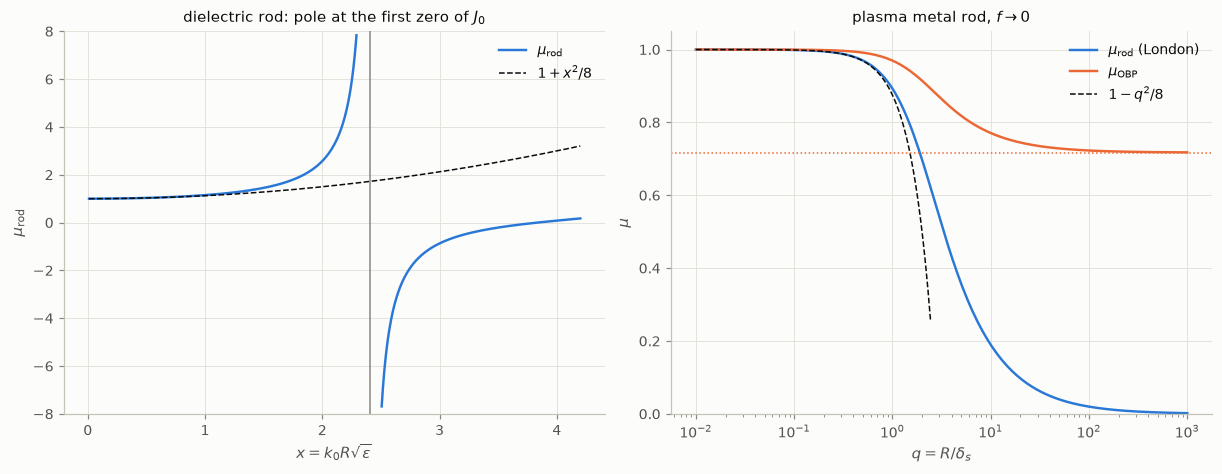

In [3]:
def mu_rod(x):
    """Average of H_z over the rod for a uniform applied field: 2 J1(x) / (x J0(x)); x may be complex."""
    return 2 * jv(1, x) / (x * jv(0, x))


def mu_london(qq):
    """Plasma-metal limit x = i q, written with scaled Bessel functions so that it does not overflow."""
    return 2 * ive(1, qq) / (qq * ive(0, qq))


def mu_obp(f, eps, rad=R):
    x = TWO_PI * f * np.sqrt(complex(eps)) * rad
    return 1 - np.pi * rad**2 + np.pi * rad**2 * mu_rod(x)


# dielectric limit
x = 0.02
check("dielectric, small x: (mu_rod - 1) / (x^2 / 8) - 1", (mu_rod(x) - 1) / (x**2 / 8) - 1, 1e-4)
below, above = mu_rod(J01 * (1 - 1e-4)), mu_rod(J01 * (1 + 1e-4))
print(f"dielectric: mu_rod just below and above the first zero of J0 (x = {J01:.4f}): {below:.1f}, {above:.1f}")
assert below > 1e3 and above < -1e3
f_res = J01 / (TWO_PI * R * np.sqrt(12.0))
print(f"single-rod pole for eps_r = 12: a/lambda_0 = {f_res:.4f} (the lattice of notebook 03 places it a little higher)")

# plasma-metal limit: frequency independent, equals London's formula
a_lp = 3.0
print("plasma metal, a/lambda_p = 3 (q = %.3f): mu_rod from the Drude permittivity against London's limit" % q_of(a_lp))
for f in (1e-1, 1e-2, 1e-3, 1e-5):
    eps = drude(f, a_lp)
    print(f"    f = {f:7.0e}: eps_m = {eps.real:12.4g}, mu_rod = {mu_rod(TWO_PI * f * R * np.sqrt(complex(eps))).real:.8f}, London {mu_london(q_of(a_lp)):.8f}")
eps = drude(1e-5, a_lp)
check("plasma metal at f = 1e-5: mu_rod against London (relative)", mu_rod(TWO_PI * 1e-5 * R * np.sqrt(complex(eps))).real / mu_london(q_of(a_lp)) - 1, 1e-9)
eps = drude(1e-2, a_lp)
check("plasma metal at f = 1e-2: against London (relative; the departure is of order (f / f_p)^2)", mu_rod(TWO_PI * 1e-2 * R * np.sqrt(complex(eps))).real / mu_london(q_of(a_lp)) - 1, 2e-5)
check("small q: 1 - mu_london = q^2 / 8 (relative, q = 0.05)", (1 - mu_london(0.05)) / (0.05**2 / 8) - 1, 1e-3)
# perfect conductor
for qq in (10.0, 100.0, 1e4):
    print(f"perfect-conductor limit: q = {qq:7.0f}, q mu_rod = {qq * mu_london(qq):.5f}")
check("q mu_rod -> 2 for q = 1e4", 1e4 * mu_london(1e4), 1e-3, 2.0)
check("mu_OBP -> 1 - eta for q = 1e4", 1 - FILL + FILL * mu_london(1e4), 1e-4, 1 - FILL)
qs = np.logspace(-2, 3, 200)
assert (np.diff(mu_london(qs)) < 0).all() and (mu_london(qs) > 0).all() and (mu_london(qs) < 1).all()

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
xx = np.linspace(0.01, 4.2, 800)
yy = mu_rod(xx); yy[np.abs(yy) > 8] = np.nan
axs[0].plot(xx, yy, color=CAT[0], label=r"$\mu_{\rm rod}$")
axs[0].plot(xx, 1 + xx**2 / 8, color=INK, ls="--", lw=1, label=r"$1+x^2/8$")
axs[0].axvline(J01, color=MUTED, lw=1); axs[0].set(xlabel=r"$x=k_0R\sqrt{\varepsilon}$", ylabel=r"$\mu_{\rm rod}$", ylim=(-8, 8), title="dielectric rod: pole at the first zero of $J_0$"); axs[0].legend()
axs[1].semilogx(qs, mu_london(qs), color=CAT[0], label=r"$\mu_{\rm rod}$ (London)")
axs[1].semilogx(qs, 1 - FILL + FILL * mu_london(qs), color=CAT[1], label=r"$\mu_{\rm OBP}$")
axs[1].semilogx(qs, np.where(qs < 2.5, 1 - qs**2 / 8, np.nan), color=INK, ls="--", lw=1, label=r"$1-q^2/8$")
axs[1].axhline(1 - FILL, color=CAT[1], ls=":", lw=1); axs[1].set(xlabel=r"$q=R/\delta_s$", ylabel=r"$\mu$", ylim=(0, 1.05), title="plasma metal rod, $f\\to0$"); axs[1].legend()
plt.show()

The dielectric rod resonates, and for a metal there is nothing to resonate: $\mu_{\rm rod}$ decreases monotonically from 1 to 0 as the rod gets thicker than the skin depth, which is the perfect-conductor limit of the printed table. The diamagnetism of a metal rod is therefore bounded, and the bound is a statement about flux: whatever the frequency, a lattice cannot expel more than the area of its rods, so $\mu_{\rm OBP}\ge1-\eta$.

## 2. TE lattice of Drude rods: second-order coefficients

Same method as notebook 03: the driven response $\varepsilon(\omega,\mathbf k)$ of `rodlattice.driven`, with the Taylor coefficients in $|\mathbf k|$ along $\Gamma X$ and $\Gamma M$ obtained as Cauchy integrals on a circle of complex $\kappa$, now with complex coefficients because a lossy rod gives complex ones. The cell below defines the helpers and checks them against themselves (independence of the circle's radius, vanishing odd orders, the redundancy of notebook 03).

In [4]:
def eps_parts(k0, kap, phi, eps, M=5, rad=R):
    """[across-across, along-along, across-along] components of the TE tensor at k = kap (cos phi, sin phi)."""
    kh = np.array([np.cos(phi), np.sin(phi)])
    th = np.array([-kh[1], kh[0]])
    e = rl.driven(k0, kap * kh, rad, eps, "TE", M=M)[0]
    return np.array([th @ e @ th, kh @ e @ kh, th @ e @ kh])


def taylor(fun, rho, n=16, orders=(0, 1, 2, 3, 4)):
    """Taylor coefficients at kappa = 0 of an analytic function, from n samples on the circle |kappa| = rho."""
    th = (np.arange(n) + 0.5) * TWO_PI / n
    vals = np.array([fun(rho * np.exp(1j * t)) for t in th])
    return np.array([(vals * np.exp(-1j * m * th)[:, None]).mean(axis=0) / rho**m for m in orders])


def te_coefficients(f, eps, rho=0.2, M=5, rad=R):
    """eps_T(w, 0), tau, delta, lambda (complex for a lossy rod) at frequency f; also two consistency numbers."""
    k0 = TWO_PI * f
    cX = taylor(lambda kap: eps_parts(k0, kap, 0.0, eps, M, rad), rho)
    cM = taylor(lambda kap: eps_parts(k0, kap, np.pi / 4, eps, M, rad), rho)
    return dict(eps=cX[0, 0], tau=0.5 * (cX[2, 0] + cM[2, 0]), delta=0.5 * (cM[2, 0] - cX[2, 0]),
                lam=0.5 * (cX[2, 1] + cM[2, 1]),
                trace=abs((cX[2, 0] + cX[2, 1]) - (cM[2, 0] + cM[2, 1])),
                odd=max(np.abs(cX[1]).max(), np.abs(cX[3]).max(), np.abs(cM[1]).max()))


k2 = lambda f: (TWO_PI * f) ** 2
c_a, c_b = te_coefficients(1e-3, drude(1e-3, 3.0, 1 / 300), rho=0.1), te_coefficients(1e-3, drude(1e-3, 3.0, 1 / 300), rho=0.3)
check("lossy Drude rod: coefficients do not depend on the radius of the circle (k0^2 tau, relative)", c_a["tau"] / c_b["tau"] - 1, 1e-8)
check("lossy Drude rod: odd orders vanish (relative to k0^2 |tau| scale)", k2(1e-3) * c_a["odd"], 1e-8)
check("lossy Drude rod: the redundancy c_T + c_L equal on GX and GM (relative to tau)", c_a["trace"] / abs(c_a["tau"]), 1e-8)

PASS  lossy Drude rod: coefficients do not depend on the radius of the circle (k0^2 tau, relative): got 2.32991e-12-1.15957e-12j, target 0, |diff| 2.60e-12 <= 1e-08
PASS  lossy Drude rod: odd orders vanish (relative to k0^2 |tau| scale): got 4.30366e-13, target 0, |diff| 4.30e-13 <= 1e-08
PASS  lossy Drude rod: the redundancy c_T + c_L equal on GX and GM (relative to tau): got 3.80217e-13, target 0, |diff| 3.80e-13 <= 1e-08


### 2a. Check against a plane-wave solution

Notebook 03 tested the TE driven response for dielectric rods only, and nothing has tested it with a metal rod. A metal rod has $|\varepsilon|\gg1$ and a negative real part, which is the hard case for a plane-wave expansion. The solution below writes the problem for $H_z$ and expands in plane waves with the Fourier coefficients of the disk. Two ways of treating the factor $1/\varepsilon$ in the curl equation are used: the Laurent rule (the convolution matrix of the function $1/\varepsilon$) and the inverse rule (the inverse of the convolution matrix of $\varepsilon$). The mean field $\langle\mathbf E\rangle$ is taken from Faraday's law and Ampere's law gives $\langle\mathbf D\rangle$, so that the $2\times2$ tensor is $\langle\mathbf D\rangle\langle\mathbf E\rangle^{-1}$ for two sources, one along $\mathbf k$ and one across it. The plane-wave solution knows nothing of multipole expansions. The disk is resolved by the cutoff (the largest wavenumber times $R$ is $2\pi nR\approx1.9n$), but the interface discontinuity of $\varepsilon$ makes the convergence slow and, with these contrasts, not monotonic.

In [5]:
def _fourier_matrix(n, rad, val):
    """Convolution matrix of 1 + (val - 1) * disk on the plane waves with integer indices |m| <= n, and the vectors G."""
    m = np.arange(-n, n + 1)
    M1, M2 = np.meshgrid(m, m, indexing="ij")
    G = TWO_PI * np.stack([M1.ravel(), M2.ravel()], 1)
    D = G[:, None, :] - G[None, :, :]
    g = np.hypot(D[..., 0], D[..., 1]) * rad
    form = np.where(g < 1e-9, 1.0, 2 * j1(np.where(g < 1e-9, 1.0, g)) / np.where(g < 1e-9, 1.0, g))
    return G, np.eye(len(G)) + (val - 1) * np.pi * rad**2 * form


def pw_te(k0, kv, eps, n, rule="inverse", rad=R):
    """TE 2x2 tensor of a square lattice of disks (mu = 1) from H_z plane waves, rule = 'inverse' or 'laurent'."""
    G, E = _fourier_matrix(n, rad, eps)
    X = np.linalg.inv(E) if rule == "inverse" else _fourier_matrix(n, rad, 1 / eps)[1]
    i0 = len(G) // 2
    k = np.asarray(kv, float)
    kg = k[None, :] + G
    kn = np.hypot(*k)
    lop = (kg @ kg.T) * X - k0**2 * np.eye(len(G))
    Em, Dm = [], []
    for J0 in (k / kn, np.array([-k[1], k[0]]) / kn):
        cross = kg[:, 0] * J0[1] - kg[:, 1] * J0[0]
        u = np.linalg.solve(lop, 1j * cross * X[:, i0])
        W = 1j * np.stack([kg[:, 1], -kg[:, 0]], 1) * u[:, None]
        W[i0] -= J0
        E0 = (1j / k0) * (X[i0] @ W)
        Em.append(E0)
        Dm.append((kn**2 * E0 - k * (k @ E0) - 1j * k0 * J0) / k0**2)
    return np.array(Dm).T @ np.linalg.inv(np.array(Em).T)


# the plane-wave code on a case where the answer is known: a dielectric rod at the static limit (Rayleigh's series, notebook 03)
b = (4.0 - 1) / (4.0 + 1)
rayleigh = 1 + 2 * FILL / (1 / b - FILL - 0.305827 * b * FILL**4 - 0.013362 * b * FILL**8)
for rule in ("inverse", "laurent"):
    e_pw = pw_te(TWO_PI * 1e-3, (2e-3, 1e-3), 4.0, 14, rule)
    check(f"plane-wave code, eps_r = 4, f = 1e-3, n = 14, {rule} rule: static eps_T against Rayleigh's series (relative; the error falls like 1/n)", e_pw[0, 0].real / rayleigh - 1, 1e-2)

t0 = time.perf_counter()
points = [("a", 0.10, 1.0, 1 / 30, (0.9, 0.4)), ("b", 0.05, 0.4, 1 / 30, (0.9, 0.4)), ("c", 0.20, 0.5, 1 / 30, (0.7, -0.3)), ("d", 0.10, 3.0, 1 / 300, (0.9, 0.4))]
sizes = (10, 14, 18, 22, 26, 30)
pw_err = {}
print("lossy Drude rods, TE tensor, multiple scattering (M = 6) against plane waves; error = max |difference| / max |element|")
for tag, f, a_lp, g, kv in points:
    eps, k0 = drude(f, a_lp, g), TWO_PI * f
    ms = rl.driven(k0, kv, R, eps, "TE", M=6)[0]
    ms4 = rl.driven(k0, kv, R, eps, "TE", M=4)[0]
    err = {rule: [np.abs(pw_te(k0, kv, eps, n, rule) - ms).max() / np.abs(ms).max() for n in sizes] for rule in (("laurent", "inverse") if tag in "ab" else ("laurent",))}
    pw_err[tag] = err
    print(f"  ({tag}) f = {f}, a/lambda_p = {a_lp}, eps_m = {eps.real:.1f}{eps.imag:+.1f}i, k = {kv}; MS M = 4 vs 6: {np.abs(ms4 - ms).max() / np.abs(ms).max():.1e}")
    for rule, e in err.items():
        print(f"      {rule:8s} n = " + "  ".join(f"{n}: {v:.4f}" for n, v in zip(sizes, e)))
print(f"plane-wave runs: {time.perf_counter() - t0:.0f} s")
for eps_t in (4.0, drude(0.1, 1.0, 1 / 30), drude(0.1, 3.0, 1 / 300)):
    ev = np.linalg.eigvals(_fourier_matrix(10, R, eps_t)[1])
    print(f"  smallest |eigenvalue| of the convolution matrix of eps (n = 10) for eps = {eps_t:.1f}: {np.abs(ev).min():.3f} (largest {np.abs(ev).max():.1f})")
    if abs(eps_t) > 10:
        assert np.abs(ev).min() < 0.5
for tag in "abcd":
    e = pw_err[tag]["laurent"]
    assert np.mean(e[-3:]) < np.mean(e[:3])                       # the error trends down
check("(a) |eps| = 94, Laurent rule: error at n = 30", pw_err["a"]["laurent"][-1], 0.02)
check("(b) |eps| = 61, Laurent rule: error at n = 30", pw_err["b"]["laurent"][-1], 0.02)
check("(c) |eps| = 5, Laurent rule: error at n = 30", pw_err["c"]["laurent"][-1], 0.02)
check("(d) |eps| = 890, Laurent rule: error at n = 30 (slower, as expected for the larger contrast)", pw_err["d"]["laurent"][-1], 0.05)
assert np.mean(pw_err["a"]["inverse"][-3:]) < np.mean(pw_err["a"]["inverse"][:3])
check("(a) inverse rule: error at n = 30", pw_err["a"]["inverse"][-1], 0.06)

PASS  plane-wave code, eps_r = 4, f = 1e-3, n = 14, inverse rule: static eps_T against Rayleigh's series (relative; the error falls like 1/n): got 0.00821409, target 0, |diff| 8.21e-03 <= 1e-02
PASS  plane-wave code, eps_r = 4, f = 1e-3, n = 14, laurent rule: static eps_T against Rayleigh's series (relative; the error falls like 1/n): got -0.00207477, target 0, |diff| 2.07e-03 <= 1e-02
lossy Drude rods, TE tensor, multiple scattering (M = 6) against plane waves; error = max |difference| / max |element|


  (a) f = 0.1, a/lambda_p = 1.0, eps_m = -89.0+30.0i, k = (0.9, 0.4); MS M = 4 vs 6: 1.4e-06
      laurent  n = 10: 0.0223  14: 0.0197  18: 0.0158  22: 0.0139  26: 0.0101  30: 0.0101
      inverse  n = 10: 0.1640  14: 0.0781  18: 0.0820  22: 0.0530  26: 0.0404  30: 0.0394


  (b) f = 0.05, a/lambda_p = 0.4, eps_m = -58.8+15.9i, k = (0.9, 0.4); MS M = 4 vs 6: 1.4e-06
      laurent  n = 10: 0.0231  14: 0.0176  18: 0.0184  22: 0.0081  26: 0.0121  30: 0.0086
      inverse  n = 10: 0.1740  14: 0.0902  18: 0.0448  22: 0.0559  26: 0.0273  30: 0.0412


  (c) f = 0.2, a/lambda_p = 0.5, eps_m = -5.2+0.5i, k = (0.7, -0.3); MS M = 4 vs 6: 5.0e-06
      laurent  n = 10: 0.0206  14: 0.0585  18: 0.0267  22: 0.0105  26: 0.0125  30: 0.0099


  (d) f = 0.1, a/lambda_p = 3.0, eps_m = -890.1+89.1i, k = (0.9, 0.4); MS M = 4 vs 6: 1.2e-06
      laurent  n = 10: 0.0458  14: 0.0527  18: 0.0606  22: 0.0562  26: 0.0347  30: 0.0287
plane-wave runs: 39 s
  smallest |eigenvalue| of the convolution matrix of eps (n = 10) for eps = 4.0: 1.000 (largest 4.0)
  smallest |eigenvalue| of the convolution matrix of eps (n = 10) for eps = -89.0+30.0j: 0.323 (largest 93.9)
  smallest |eigenvalue| of the convolution matrix of eps (n = 10) for eps = -890.1+89.1j: 0.108 (largest 894.5)
PASS  (a) |eps| = 94, Laurent rule: error at n = 30: got 0.0101, target 0, |diff| 1.01e-02 <= 2e-02
PASS  (b) |eps| = 61, Laurent rule: error at n = 30: got 0.00863033, target 0, |diff| 8.63e-03 <= 2e-02
PASS  (c) |eps| = 5, Laurent rule: error at n = 30: got 0.00987281, target 0, |diff| 9.87e-03 <= 2e-02
PASS  (d) |eps| = 890, Laurent rule: error at n = 30 (slower, as expected for the larger contrast): got 0.028672, target 0, |diff| 2.87e-02 <= 5e-02
PASS  (a) inver

Multiple scattering and plane waves agree to within the printed errors, which are of the order of a percent for the Laurent rule and larger for the largest contrast, and which fall on average as the number of waves grows but not monotonically. Two things make this a good test and an unsharp one. It is the first comparison for metal rods between two methods that share no code, a multipole series about the center of the rod and a Fourier series about nothing, and the test point includes loss. And it is the plane-wave side that is not converged: the printed errors are many times the difference between multiple scattering with four and six orders, which is the measure of the multiple-scattering convergence. The inverse rule, which was used for dielectric rods, is erratic here. The printed smallest eigenvalues are consistent with an explanation: the truncated convolution matrix of $\varepsilon$ is a matrix with eigenvalues inside the numerical range of $\varepsilon$, which for a metal contains values much smaller than one, and the inverse rule amplifies those modes; for the dielectric rod its smallest eigenvalue is one. This explanation was not tested further. The Laurent rule for $1/\varepsilon$ is smoother here and is the one to read.

### 2b. The coefficients over four decades of $a/\lambda_p$

The frequency is $f=10^{-3}$, far below the electric dipole plasmon of the rods ($f\approx f_p/\sqrt2$ for a rod in vacuum) for every $a/\lambda_p\ge0.03$, and the results are shown as $k_0^2\tau$ and $k_0^2\delta$, the dimensionless quantities that enter $\mu=1/(1-k_0^2\tau)$. The comparison curves are $1-1/\mu_{\rm OBP}$ and the loop law $\eta(\varepsilon_m-1)k_0^2R^2/8=-\eta q^2/8$ of notebook 03, with the permittivity of the metal.

25 lattices in 1 s
collisionless Drude rods, TE, f = 1e-3 (k0^2 times each coefficient)
  a/lp       q      eps_m        k0^2 tau   1 - 1/mu_OBP   loop law   k0^2 delta   k0^2 lambda
  0.030    0.057        -899    -0.000114    -0.000113    -0.000113    -4.09e-07     1.72e-07
  0.065    0.122   -4.18e+03    -0.000524    -0.000523    -0.000525    -4.07e-07     1.71e-07
  0.139    0.262   -1.94e+04    -0.002414    -0.002413    -0.002435    -4.07e-07     1.70e-07
  0.300    0.565      -9e+04    -0.010848    -0.010847    -0.011302    -4.07e-07     1.70e-07
  0.646    1.218   -4.18e+05    -0.043969    -0.043968    -0.052458    -4.07e-07     1.70e-07
  1.392    2.625   -1.94e+06    -0.130132    -0.130131    -0.243490    -4.06e-07     1.70e-07
  3.000    5.655      -9e+06    -0.237745    -0.237745    -1.130179    -4.06e-07     1.70e-07
  6.463   12.183   -4.18e+07    -0.312810    -0.312810    -5.245825    -4.06e-07     1.70e-07
 13.925   26.248   -1.94e+08    -0.354304    -0.354304   -24.3489

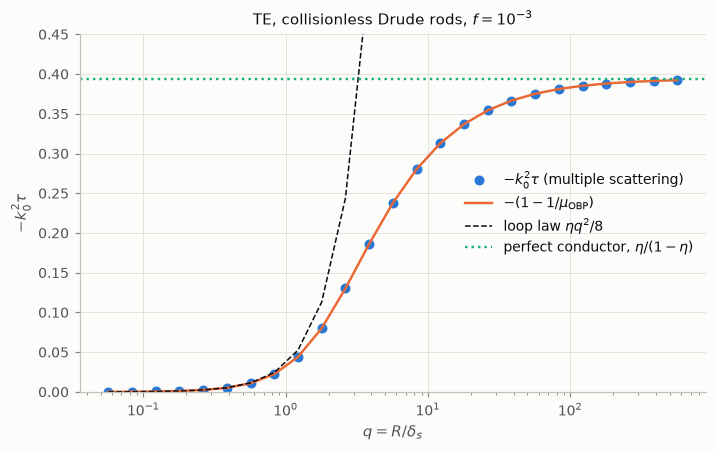

(k0^2 tau - (1 - 1/mu_OBP)) / k0^2, units of a^2, at f = 1e-3 and 1e-4:
    a/lambda_p =   0.3 (q =   0.57): -0.01872  -0.01872
PASS  residual over k0^2 is the same at f = 1e-3 and 1e-4 (O(k0^2)), a/lambda_p = 0.3: got -3.57571e-06, target 0, |diff| 3.58e-06 <= 5e-04


    a/lambda_p =   3.0 (q =   5.65): +0.00168  +0.00157
PASS  residual over k0^2 is the same at f = 1e-3 and 1e-4 (O(k0^2)), a/lambda_p = 3.0: got 0.000101932, target 0, |diff| 1.02e-04 <= 5e-04


    a/lambda_p =  30.0 (q =  56.55): +0.00793  +0.00793
PASS  residual over k0^2 is the same at f = 1e-3 and 1e-4 (O(k0^2)), a/lambda_p = 30.0: got 3.54706e-08, target 0, |diff| 3.55e-08 <= 5e-04


In [6]:
F_LOW = 1e-3
A_LP = np.logspace(np.log10(0.03), np.log10(300), 25)
t0 = time.perf_counter()
sc = [te_coefficients(F_LOW, drude(F_LOW, a), rho=0.2, M=5) for a in A_LP]
print(f"{len(A_LP)} lattices in {time.perf_counter() - t0:.0f} s")
K2 = k2(F_LOW)
ktau = np.array([K2 * c["tau"] for c in sc])
kdel = np.array([K2 * c["delta"] for c in sc])
klam = np.array([K2 * c["lam"] for c in sc])
obp = np.array([1 - 1 / mu_obp(F_LOW, drude(F_LOW, a)) for a in A_LP])
loop = -FILL * q_of(A_LP) ** 2 / 8
print("collisionless Drude rods, TE, f = 1e-3 (k0^2 times each coefficient)")
print("  a/lp       q      eps_m        k0^2 tau   1 - 1/mu_OBP   loop law   k0^2 delta   k0^2 lambda")
for i in range(0, len(A_LP), 2):
    print(f"{A_LP[i]:7.3f} {q_of(A_LP[i]):8.3f} {drude(F_LOW, A_LP[i]).real:11.3g} {ktau[i].real:12.6f} {obp[i].real:12.6f} {loop[i]:12.6f} {kdel[i].real:12.2e} {klam[i].real:12.2e}")
assert np.abs(ktau.imag).max() < 1e-9 * np.abs(ktau).max()
check("collisionless rods: k0^2 tau tracks 1 - 1/mu_OBP over four decades (max |difference|)", np.abs(ktau.real - obp.real).max(), 3e-5)
assert (np.diff(ktau.real) < 0).all()
assert np.argmax(np.abs(ktau.real - obp.real)) == len(A_LP) - 1          # the largest departure is at the largest |eps_m|

fig, ax = plt.subplots()
ax.semilogx(q_of(A_LP), -ktau.real, "o", color=CAT[0], label=r"$-k_0^2\tau$ (multiple scattering)")
ax.semilogx(q_of(A_LP), -obp.real, color=CAT[1], label=r"$-(1-1/\mu_{\rm OBP})$")
ax.semilogx(q_of(A_LP), -loop, color=INK, ls="--", lw=1, label=r"loop law $\eta q^2/8$")
ax.axhline(FILL / (1 - FILL), color=CAT[2], ls=":", label=r"perfect conductor, $\eta/(1-\eta)$")
ax.set(xlabel=r"$q=R/\delta_s$", ylabel=r"$-k_0^2\tau$", ylim=(0, 0.45), title=r"TE, collisionless Drude rods, $f=10^{-3}$"); ax.legend(loc="center right")
plt.show()

# the residual is O(k0^2): the same number of a^2 at two frequencies a factor of 10 apart (100 in k0^2)
print("(k0^2 tau - (1 - 1/mu_OBP)) / k0^2, units of a^2, at f = 1e-3 and 1e-4:")
for a in (0.3, 3.0, 30.0):
    row = []
    for f in (1e-3, 1e-4):
        e = drude(f, a)
        row.append(((k2(f) * te_coefficients(f, e, rho=0.2, M=5)["tau"]).real - (1 - 1 / mu_obp(f, e).real)) / k2(f))
    print(f"    a/lambda_p = {a:5.1f} (q = {q_of(a):6.2f}): {row[0]:+.5f}  {row[1]:+.5f}")
    check(f"residual over k0^2 is the same at f = 1e-3 and 1e-4 (O(k0^2)), a/lambda_p = {a}", row[0] - row[1], 5e-4)
    assert abs(row[0]) < 0.03

The multiple-scattering $k_0^2\tau$ follows $1-1/\mu_{\rm OBP}$ over the whole range, from the loop law at small $q$ to flux exclusion at large $q$, within the tolerance of the printed check. This is an agreement with a closed form, and a sharp one (the check resolves a few parts in $10^5$ over four decades). A reason that it should be exact in this limit, offered as the likely one: for TE in two dimensions $H_z$ outside the rods is uniform to $O(k_0^2)$ for any rods and any lattice, the $m=0$ scattering coefficient of a rod is $O[(k_0R)^2](1-\mu_{\rm rod})$, and only the macroscopic $\mathbf G=0$ lattice term is $O(1/k_0^2)$; so $\mu_{\rm OBP}$, averaged over the cell, is the quasi-static permeability of the lattice, not a mean-field approximation to it. The cell's last printout supports this: the difference $k_0^2\tau-(1-1/\mu_{\rm OBP})$, divided by $k_0^2$, is the same at $f=10^{-3}$ and $10^{-4}$ (to within the printed check tolerance), that is, the departure from $1-1/\mu_{\rm OBP}$ is of order $k_0^2$. The test is therefore a precision validation of `rodlattice.driven` with metal rods at $f\to0$ and complements the plane-wave test of section 2a at finite frequency. It does not follow the loop law beyond $q\approx1$, where the loop law with the permittivity of the metal grows without bound and the real response saturates. The largest departure is in the last row, where $|\varepsilon_m|\approx10^{11}$; it is read as the limit of what double precision resolves in the rod functions there, which was not tested. Note what is compared: $k_0^2\tau$ is the quantity that enters $\mu_{zz}=1/(1-k_0^2\tau)$, so $k_0^2\tau=1-1/\mu_{\rm OBP}$ means that the lattice returns the permeability $\mu_{\rm OBP}$ itself, and not $\mu_{\rm OBP}-1$ in place of $1-1/\mu_{\rm OBP}$. The two differ beyond first order in $\eta$ and in $q$, and it is $1-1/\mu_{\rm OBP}$ that matches the printed numbers.

### 2c. The two limits and the contrast with a dielectric rod

(b) For large $q$ and $f\to0$ the rods exclude $H_z$: in statics $H_z$ is uniform outside perfectly conducting rods, so the induction averaged over the cell is $(1-\eta)H$ and $\mu=1-\eta$, which gives $k_0^2(\tau\mp\delta)\to1-1/(1-\eta)=-\eta/(1-\eta)$ along both axes, since $k_0^2\delta\to0$ with $f^2$. The approach is slow, like $\delta_s/R$: expanding $\mu_{\rm OBP}$ at large $q$ with $\mu_{\rm rod}\to2/q$ gives a correction $2\eta/[q(1-\eta)^2]$. The cell fits $k_0^2\tau=L+c_1/q+c_2/q^2$ through three values of $q$ between 50 and 300 and compares $L$ and $c_1$ with these.

(c) For small $q$ the loop law, $k_0^2\tau=-\eta q^2/8$, should hold up to the background term $k_0^2\times O(10^{-2}a^2)$ of notebook 03, which is why the comparison is made in terms of the difference divided by $k_0^2$.

In [7]:
sel = [i for i, a in enumerate(A_LP) if 25 < a < 150]
qq = q_of(A_LP[sel])
sel3 = [sel[0], sel[len(sel) // 2], sel[-1]]
Lfit = np.linalg.solve(np.vander(1 / q_of(A_LP[sel3]), 3, increasing=True), ktau[sel3].real)
print(f"large q: fit through a/lambda_p = {A_LP[sel3].round(1).tolist()}: L = {Lfit[0]:.6f}, c1 = {Lfit[1]:.4f}, c2 = {Lfit[2]:.3f}")
print(f"         flux exclusion -eta/(1 - eta) = {-FILL / (1 - FILL):.6f}; predicted c1 = 2 eta / (1 - eta)^2 = {2 * FILL / (1 - FILL)**2:.4f}")
check("(b) extrapolated k0^2 tau at q -> infinity against 1 - 1/(1 - eta)", Lfit[0], 2e-4, -FILL / (1 - FILL))
check("(b) coefficient of 1/q against the mean-field expansion (relative)", Lfit[1] / (2 * FILL / (1 - FILL)**2) - 1, 0.03)
big = sc[-3]
check("(b) k0^2 (tau - delta) and k0^2 (tau + delta) coincide at large q (their difference, which is 2 k0^2 delta)", 2 * K2 * abs(big["delta"]), 1e-6)
print(f"(b) at a/lambda_p = {A_LP[-3]:.0f}: k0^2 (tau - delta) = {(K2 * (big['tau'] - big['delta'])).real:.6f}, k0^2 (tau + delta) = {(K2 * (big['tau'] + big['delta'])).real:.6f}")

print("(c) (k0^2 tau - loop law) / k0^2 at f = 1e-4, units of a^2 (the loop law is the leading term; the difference is the background of notebook 03 plus the next order in q):")
bgs = {}
for a in (0.003, 0.01, 0.03):
    c = te_coefficients(1e-4, drude(1e-4, a), rho=0.2, M=5)
    bgs[a] = ((k2(1e-4) * c["tau"]).real + FILL * q_of(a) ** 2 / 8) / k2(1e-4)
    print(f"    a/lambda_p = {a:6.3f} (q = {q_of(a):.4f}): difference / k0^2 = {bgs[a]:+.4f}")
check("(c) the difference from the loop law over k0^2 at the smallest q is the background of notebook 03, about -0.015 a^2", bgs[0.003], 0.003, -0.015)
check("(c) ... and has converged as q -> 0 (a/lambda_p = 0.003 against 0.01)", bgs[0.01] - bgs[0.003], 3e-3)
check("(c) k0^2 tau against the loop law at a/lambda_p = 0.03 (relative)", ktau[0].real / loop[0] - 1, 1e-2)
check("(c) k0^2 tau against the loop law at a/lambda_p = 0.065 (relative)", ktau[1].real / loop[1] - 1, 1e-2)

dl_metal = [(sc[i]["delta"].real, sc[i]["lam"].real) for i in (3, 9, 15)]
dl_diel = te_coefficients(F_LOW, 1000.0, rho=0.2, M=5)
print(f"delta and lambda (units of a^2) for metal rods at a/lambda_p = {A_LP[3]:.2f}, {A_LP[9]:.2f}, {A_LP[15]:.2f}: " + ", ".join(f"({d:.5f}, {l:.5f})" for d, l in dl_metal)
      + f"; for a dielectric rod with eps_r = 1000: ({dl_diel['delta'].real:.5f}, {dl_diel['lam'].real:.5f})")
for d, l in dl_metal:
    assert abs(d / dl_diel["delta"].real - 1) < 0.1 and abs(l / dl_diel["lam"].real - 1) < 0.1      # the same background as a dielectric rod of large permittivity

print("\nfrequency dependence of k0^2 tau (a/lambda_p = 1 plasma metal; eps_r = 12 dielectric), R = 0.3")
FS = np.array([1e-3, 2e-3, 4e-3])
plasma_f = np.array([(K := k2(f)) * te_coefficients(f, drude(f, 1.0), rho=0.2)["tau"] for f in FS]).real
diel_f = np.array([k2(f) * te_coefficients(f, 12.0, rho=0.2)["tau"] for f in FS]).real
for f, p, d in zip(FS, plasma_f, diel_f):
    print(f"  f = {f:.0e}: plasma {p:+.7f}   dielectric {d:+.3e}   dielectric / f^2 = {d / f**2:.4f}")
check("plasma metal: k0^2 tau is frequency independent (f = 2e-3 over 1e-3, minus 1)", plasma_f[1] / plasma_f[0] - 1, 1e-3)
check("plasma metal: ... and f = 4e-3 over 1e-3, minus 1", plasma_f[2] / plasma_f[0] - 1, 1e-3)
check("dielectric rod: k0^2 tau grows like f^2 (ratio for a factor 2 in f)", diel_f[1] / diel_f[0], 0.02, 4.0)
check("dielectric rod: ... and for a factor 4", diel_f[2] / diel_f[0], 0.2, 16.0)
assert diel_f[0] > 0 and plasma_f[0] < 0

large q: fit through a/lambda_p = [30.0, 64.6, 139.2]: L = -0.394200, c1 = 1.0988, c2 = -1.374
         flux exclusion -eta/(1 - eta) = -0.394201; predicted c1 = 2 eta / (1 - eta)^2 = 1.0992
PASS  (b) extrapolated k0^2 tau at q -> infinity against 1 - 1/(1 - eta): got -0.3942, target -0.394201, |diff| 1.20e-06 <= 2e-04
PASS  (b) coefficient of 1/q against the mean-field expansion (relative): got -0.000323247, target 0, |diff| 3.23e-04 <= 3e-02
PASS  (b) k0^2 (tau - delta) and k0^2 (tau + delta) coincide at large q (their difference, which is 2 k0^2 delta): got 8.12987e-07, target 0, |diff| 8.13e-07 <= 1e-06
(b) at a/lambda_p = 139: k0^2 (tau - delta) = -0.390033, k0^2 (tau + delta) = -0.390034
(c) (k0^2 tau - loop law) / k0^2 at f = 1e-4, units of a^2 (the loop law is the leading term; the difference is the background of notebook 03 plus the next order in q):
    a/lambda_p =  0.003 (q = 0.0057): difference / k0^2 = -0.0167
    a/lambda_p =  0.010 (q = 0.0188): difference / k0^2 = -0.0

delta and lambda (units of a^2) for metal rods at a/lambda_p = 0.09, 0.95, 9.49: (-0.01030, 0.00432), (-0.01030, 0.00432), (-0.01030, 0.00432); for a dielectric rod with eps_r = 1000: (-0.01024, 0.00429)

frequency dependence of k0^2 tau (a/lambda_p = 1 plasma metal; eps_r = 12 dielectric), R = 0.3


  f = 1e-03: plasma -0.0862004   dielectric +9.018e-07   dielectric / f^2 = 0.9018
  f = 2e-03: plasma -0.0862015   dielectric +3.607e-06   dielectric / f^2 = 0.9018
  f = 4e-03: plasma -0.0862060   dielectric +1.443e-05   dielectric / f^2 = 0.9019
PASS  plasma metal: k0^2 tau is frequency independent (f = 2e-3 over 1e-3, minus 1): got 1.3112e-05, target 0, |diff| 1.31e-05 <= 1e-03
PASS  plasma metal: ... and f = 4e-3 over 1e-3, minus 1: got 6.55608e-05, target 0, |diff| 6.56e-05 <= 1e-03
PASS  dielectric rod: k0^2 tau grows like f^2 (ratio for a factor 2 in f): got 4.00006, target 4, |diff| 5.63e-05 <= 2e-02
PASS  dielectric rod: ... and for a factor 4: got 16.0011, target 16, |diff| 1.13e-03 <= 2e-01


Everything the notebook claims about a metal rod in TE comes down to this contrast. For a dielectric rod $k_0^2\tau$ is positive and grows like $f^2$, so that $\mu-1\to0$ as the frequency goes to zero and the Landau-Lifshitz question is about how fast. For a plasma metal rod it is negative and constant: $\mu-1$ does not go to zero but to a number set by the ratio of rod size to skin depth, since the skin depth of a plasma does not depend on frequency. This is the law of London's electrodynamics, in a lattice. It is a static permeability, and a diamagnetic one, in the sense that a static field is partly expelled. The next section asks what losses do to it.

## 3. Losses and the static limit

With $f_\gamma>0$ the metal is a plasma only above $f_\gamma$. Below it $\varepsilon_m\to i f_p^2/(ff_\gamma)$ is ohmic, the skin depth $\delta_s=\sqrt{2/(\omega\sigma)}$ grows without bound as $f\to0$, and the rod becomes transparent to a static field, $\mu\to1$. The prediction for the ohmic regime, from the small-argument form $\mu_{\rm rod}\approx1+x^2/8$ with $x^2=k_0^2R^2\varepsilon_m$ and $\varepsilon_m\approx if_p^2/(ff_\gamma)$, is $k_0^2\tau\approx\eta\,(x^2/8)\approx i\eta q^2f/(8f_\gamma)$ with $q=2\pi Rf_p$: an imaginary part linear in $f$. The real part comes from the real part of $\varepsilon_m$ and from the next order, and the prediction is only that it vanishes faster. The cell computes $k_0^2\tau$ for $a/\lambda_p=3$ ($q=5.7$) and $f_\gamma/f_p=0$, $1/300$ and $1/30$, and for the dielectric rod of notebook 03 ($\varepsilon_r=12$), over four decades of frequency, and fits the exponents of the real and imaginary parts in the lowest decade.

68 frequency points in 2 s
exponent of the real and imaginary parts of k0^2 tau for 1e-5 <= f <= 1e-4:
  dielectric, eps_r = 12               real: f^+2.000   imaginary: none (zero to rounding)
  plasma metal                         real: f^-0.000   imaginary: none (zero to rounding)
  ohmic, f_gamma/f_p = 1/300           real: f^+1.999   imaginary: f^+0.999
  ohmic, f_gamma/f_p = 1/30            real: f^+2.000   imaginary: f^+1.000
PASS  dielectric: Re k0^2 tau ~ f^2: got 2, target 2, |diff| 7.31e-08 <= 1e-02
PASS  plasma metal: Re k0^2 tau ~ f^0 (a constant): got -5.68505e-09, target 0, |diff| 5.69e-09 <= 1e-02
PASS  ohmic, f_gamma/f_p = 1/300: Re k0^2 tau ~ f^2: got 1.99885, target 2, |diff| 1.15e-03 <= 2e-02
PASS  ohmic, f_gamma/f_p = 1/300: Im k0^2 tau ~ f^1: got 0.998903, target 1, |diff| 1.10e-03 <= 2e-02
PASS  ohmic, f_gamma/f_p = 1/30: Re k0^2 tau ~ f^2: got 2, target 2, |diff| 1.33e-06 <= 2e-02
PASS  ohmic, f_gamma/f_p = 1/30: Im k0^2 tau ~ f^1: got 0.999989, target 1, |diff|

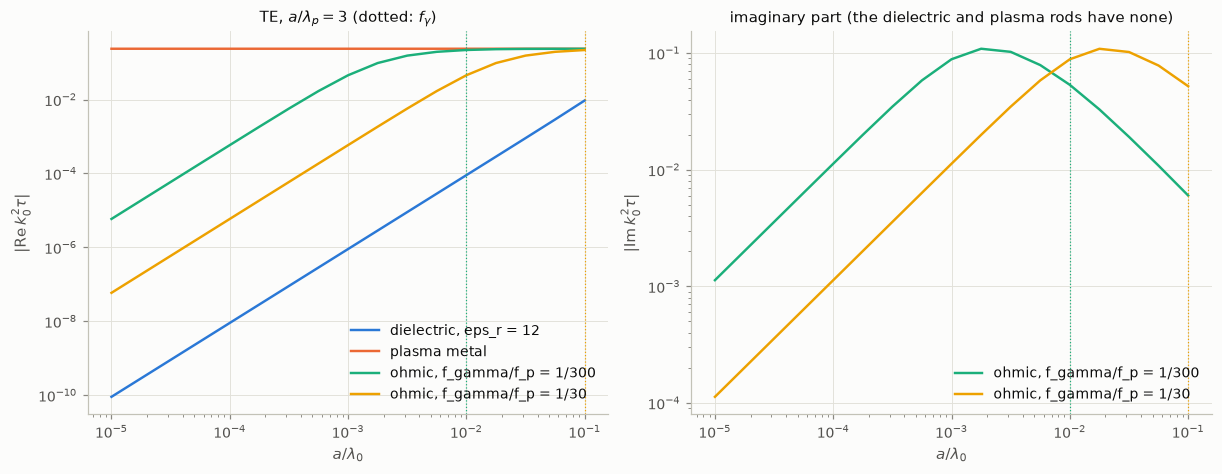

k0^2 tau at the highest and lowest frequency, a/lambda_p = 3:
  dielectric, eps_r = 12               f = 1e-5: 9.018e-11-8.773e-19j   f = 1e-1: 9.463e-03+7.191e-16j
  plasma metal                         f = 1e-5: -2.377e-01-4.790e-09j   f = 1e-1: -2.369e-01-3.424e-16j
  ohmic, f_gamma/f_p = 1/300           f = 1e-5: -5.876e-06+1.130e-03j   f = 1e-1: -2.366e-01+6.015e-03j
  ohmic, f_gamma/f_p = 1/30            f = 1e-5: -5.883e-08+1.130e-04j   f = 1e-1: -2.194e-01+5.204e-02j

ohmic rods, f_gamma / f_p = 1/100: frequency f_half at which Re k0^2 tau falls to half its plasma value (the plasma value is the f -> 0 London limit)
   a/lp       q   f_gamma   Re/plasma at f_gamma/10   f_half   f_gamma/f_half   R/delta_ohm at f_half   8/q^2 (f_half/f_gamma for R/delta_ohm = 2)


    0.3    0.57    0.003          0.011        2.88e-03            1.0               0.39     25.0176


    3.0    5.65    0.030          0.192        6.55e-03            4.6               1.87      0.2502


   30.0   56.55    0.300          0.930        1.19e-03          251.9               2.52      0.0025
PASS  a/lambda_p = 3 (the printed case): f_gamma / f_half: got 4.5784, target 4.6, |diff| 2.16e-02 <= 1e+00


In [8]:
A3 = 3.0
FG = np.logspace(-5, -1, 17)
cases = {"dielectric, eps_r = 12": lambda f: 12.0, "plasma metal": lambda f: drude(f, A3, 0.0),
         "ohmic, f_gamma/f_p = 1/300": lambda f: drude(f, A3, 1 / 300), "ohmic, f_gamma/f_p = 1/30": lambda f: drude(f, A3, 1 / 30)}
t0 = time.perf_counter()
ktau_f = {name: np.array([k2(f) * te_coefficients(f, eps(f), rho=0.2)["tau"] for f in FG]) for name, eps in cases.items()}
print(f"{len(cases) * len(FG)} frequency points in {time.perf_counter() - t0:.0f} s")


def slope(F, y):
    """Least-squares exponent of |y| against F on a log-log scale."""
    return np.polyfit(np.log(F), np.log(np.abs(y)), 1)[0]


low = FG <= 1.01e-4
print("exponent of the real and imaginary parts of k0^2 tau for 1e-5 <= f <= 1e-4:")
fit = {}
for name, y in ktau_f.items():
    re_s = slope(FG[low], y[low].real)
    im_s = slope(FG[low], y[low].imag) if np.abs(y.imag).max() > 1e-6 * np.abs(y.real).max() else np.nan
    fit[name] = (re_s, im_s)
    print(f"  {name:36s} real: f^{re_s:+.3f}   imaginary: " + ("none (zero to rounding)" if np.isnan(im_s) else f"f^{im_s:+.3f}"))
names = list(cases)
check("dielectric: Re k0^2 tau ~ f^2", fit[names[0]][0], 0.01, 2.0)
check("plasma metal: Re k0^2 tau ~ f^0 (a constant)", fit[names[1]][0], 0.01, 0.0)
for nm in names[2:]:
    check(f"{nm}: Re k0^2 tau ~ f^2", fit[nm][0], 0.02, 2.0)
    check(f"{nm}: Im k0^2 tau ~ f^1", fit[nm][1], 0.02, 1.0)
for nm, g in ((names[2], 1 / 300), (names[3], 1 / 30)):
    pred = FILL * q_of(A3) ** 2 / (8 * g * A3)
    got = ktau_f[nm][0].imag / FG[0]
    print(f"  {nm}: Im(k0^2 tau) / f at f = 1e-5: {got:.3f}, ohmic prediction eta q^2 / (8 f_gamma) = {pred:.3f}")
    check(f"{nm}: coefficient of the linear imaginary part (relative to the ohmic prediction)", got / pred - 1, 0.01)
for nm in names[:2]:
    rel = np.abs(ktau_f[nm].imag).max() / np.abs(ktau_f[nm].real).max()
    print(f"  {nm}: largest imaginary part relative to the largest real part: {rel:.1e}")
    assert rel < 1e-6

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for i, (name, y) in enumerate(ktau_f.items()):
    axs[0].loglog(FG, np.abs(y.real), color=CAT[i], label=name)
    if np.abs(y.imag).max() > 1e-6 * np.abs(y.real).max():
        axs[1].loglog(FG, np.abs(y.imag), color=CAT[i], label=name)
for ax in axs:
    ax.axvline(1 / 300 * A3, color=CAT[2], lw=0.8, ls=":"); ax.axvline(1 / 30 * A3, color=CAT[3], lw=0.8, ls=":"); ax.set_xlabel(r"$a/\lambda_0$")
axs[0].set(ylabel=r"$|{\rm Re}\,k_0^2\tau|$", title=r"TE, $a/\lambda_p=3$ (dotted: $f_\gamma$)"); axs[1].set(ylabel=r"$|{\rm Im}\,k_0^2\tau|$", title="imaginary part (the dielectric and plasma rods have none)")
axs[0].legend(loc="lower right"); axs[1].legend(loc="lower right")
plt.show()
print("k0^2 tau at the highest and lowest frequency, a/lambda_p = 3:")
for name, y in ktau_f.items():
    print(f"  {name:36s} f = 1e-5: {y[0]:.3e}   f = 1e-1: {y[-1]:.3e}")

# where does the ohmic rod stop screening? Re k0^2 tau as a fraction of its collisionless (plasma) value, f_gamma / f_p = 1/100, three rod sizes
print("\nohmic rods, f_gamma / f_p = 1/100: frequency f_half at which Re k0^2 tau falls to half its plasma value (the plasma value is the f -> 0 London limit)")
print("   a/lp       q   f_gamma   Re/plasma at f_gamma/10   f_half   f_gamma/f_half   R/delta_ohm at f_half   8/q^2 (f_half/f_gamma for R/delta_ohm = 2)")
xo = {}
for a in (0.3, 3.0, 30.0):
    qa, fgam = q_of(a), a / 100
    plas = 1 - 1 / (1 - FILL + FILL * mu_london(qa))
    frac = lambda f: (k2(f) * te_coefficients(f, drude(f, a, 1 / 100), rho=0.2, M=5)["tau"]).real / plas
    f_half = np.exp(brentq(lambda lf: frac(np.exp(lf)) - 0.5, np.log(1e-6), np.log(1e-2), xtol=1e-3))
    r_delta = qa * np.sqrt(f_half / (2 * fgam))                 # R / sqrt(2 / (omega sigma)) with eps_m = i f_p^2 / (f f_gamma); meaningful only for f << f_gamma
    xo[a] = dict(q=qa, fgam=fgam, f_half=f_half, ratio=fgam / f_half, r_delta=r_delta, at_tenth=frac(fgam / 10))
    print(f"  {a:5.1f} {qa:7.2f} {fgam:8.3f} {xo[a]['at_tenth']:14.3f} {f_half:15.2e} {fgam / f_half:14.1f} {r_delta:18.2f} {8 / qa**2:11.4f}")
assert 0.5 < xo[0.3]["ratio"] < 2                                # a thin rod: the crossover is at f_gamma itself
assert xo[0.3]["ratio"] < xo[3.0]["ratio"] < xo[30.0]["ratio"]   # the crossover moves down, away from f_gamma, as the rod grows
check("a/lambda_p = 3 (the printed case): f_gamma / f_half", xo[3.0]["ratio"], 1.0, 4.6)
assert xo[30.0]["ratio"] > 100 and xo[30.0]["at_tenth"] > 0.85       # a thick rod keeps most of its diamagnetism far below f_gamma
for a in (3.0, 30.0):
    assert 1.5 < xo[a]["r_delta"] < 3.0                           # where the ohmic skin depth is R / 2 or so, whatever the rod size

For the dielectric rod $k_0^2\tau\propto f^2$ with no imaginary part; for the plasma metal it is a negative constant with no imaginary part; for the ohmic metal the imaginary part is linear in $f$, with the coefficient of the ohmic estimate printed above, and the real part goes like $f^2$. The ohmic curves approach the plasma one at high frequency and fall away from it at low frequency, but not at $f_\gamma$ (dotted lines) in general: in the printed $a/\lambda_p=3$ case the peak of the imaginary part and the half-value of the real part sit several times below $f_\gamma$. The last table says where the crossover is for three rod sizes at the same $f_\gamma/f_p$. The reading that fits it is the ohmic skin depth: for $f\ll f_\gamma$ the metal is ohmic and $\delta_{\rm ohm}=\sqrt{2/\omega\sigma}$, so that $R/\delta_{\rm ohm}=q\sqrt{f/2f_\gamma}$, and the printed value of this ratio at the half-value frequency is about two for the two thick rods, where it applies (the table prints it for the thin rod too, but there $f_{\rm half}\approx f_\gamma$ and the ohmic form is not valid). While $\delta_{\rm ohm}$ is smaller than about $R/2$ the rod screens by eddy currents, the classical skin effect, even though $|{\rm Im}\,\varepsilon_m|>|{\rm Re}\,\varepsilon_m|$; the crossover is therefore at $f\approx8f_\gamma/q^2$ for $q\gtrsim3$ (the last printed column, which is not meant for the thin rod, $q<2$, where the crossover is at $f_\gamma$), that is, it moves down roughly like $q^{-2}$. For $a/\lambda_p=30$ the rod still has most of its plasma diamagnetism at $f_\gamma/10$ (printed). A lossy rod is therefore diamagnetic for $f$ above this skin-depth crossover and below the plasma frequency; below it the response is the dynamical one of the ohmic class: Joule heating (the imaginary part, which exceeds the real part in the printed lowest-frequency row) and a real part that vanishes like $f^2$. Only the collisionless (London) model screens a truly static field; a normal metal does not, and its eddy-current diamagnetism needs a changing flux.

## 4. The Landau-Lifshitz ratio and the size of metal magnetism

Two frequencies, $f=0.05$ and $0.1$, and $a/\lambda_p$ over about two and a half decades (from $2.5f$ to 30). At fixed frequency, varying $a/\lambda_p$ varies the plasma frequency of the metal, that is, $\varepsilon_m=1-(a/\lambda_p)^2/f^2$; the smallest value used is $2.5f$, which keeps $\varepsilon_m<-5$, away from the electric-dipole plasmon. The permeability is $\mu=1/(1-k_0^2\tau)$ with the isotropic $\tau$.

The ratio of notebook 03, $\eta(\varepsilon_r-1)R^2/8$ over the largest other coefficient, has no meaning for a metal in which the loop is not linear in $\varepsilon_m$. It is replaced by a ratio in which the magnetic part is the mean-field one,

$$\tau_{\rm mag}=\frac{1-1/\mu_{\rm OBP}}{k_0^2},\qquad {\rm LL}=\frac{|\tau_{\rm mag}|}{\max\big(|\delta|,\ |\lambda|,\ |\tau-\tau_{\rm mag}|\big)},$$

with $\mu_{\rm OBP}$ evaluated at the same $f$ and $\varepsilon_m$. That the part of $\tau$ equal to $\tau_{\rm mag}$ is "magnetic" is a model at finite frequency (it is exact as $f\to0$, section 2b): it is the part that a single rod in a uniform field has (section 1), and the other three coefficients are what is left. $\tau-\tau_{\rm mag}$ is not wholly non-magnetic: it also contains the $O(k_0^2)$ corrections to the magnetic term itself, and $\tau_{\rm mag}$ contains a small offset from $\mu_{\rm rod}=2J_1/(xJ_0)$, which gives $\mu_{\rm rod}=1+(k_0R)^2/8$ even for a vacuum rod, so about $\eta R^2/8=0.003\,a^2$ of $\tau_{\rm mag}$ is not magnetic (section 5 prints the offset). The LL estimate of the susceptibility, $\chi\sim|\varepsilon_m|(l/\lambda_0)^2$ with $l=2R$ the diameter of the rod, is shown for comparison.

scan: 2 s
       a/lp       q     eps_m     |mu - 1|   |mu_OBP - 1|   chi_LL     LL ratio
f = 0.05
     0.125    0.236      -5.2     0.00581      0.00164     0.0047        0.4
     0.216    0.408     -17.7     0.00770      0.00542     0.0159        2.4
     0.374    0.705     -55.0     0.01780      0.01596     0.0495        8.5
     0.647    1.220    -166.5     0.04340      0.04199     0.1498       28.6
     1.119    2.110    -500.2     0.09180      0.09101     0.4502       96.2
     1.936    3.650   -1499.0     0.15143      0.15125     1.3491      172.6
     3.350    6.314   -4487.8     0.20045      0.20062     4.0391      243.9
     5.795   10.923  -13432.1     0.23308      0.23340    12.0889      296.3
    10.025   18.896  -40198.3     0.25324      0.25362    36.1784      331.0
    17.342   32.689 -120297.5     0.26530      0.26571   108.2678      352.6
    30.000   56.549 -359999.0     0.27241      0.27283   323.9991      365.7
f = 0.1
     0.250    0.471      -5.2     0.02210     

   0.02        3.3     493.4    2085.6
   0.05     -         78.6     330.8
   0.10     -         18.9      80.2
PASS  large q: the LL ratio falls like 1 / f^2 (ratio at f = 0.05 over f = 0.1, a/lambda_p = 10, against 4; a consequence of the definition, section 5): got 4.12542, target 4, |diff| 1.25e-01 <= 3e-01
PASS  ... and at f = 0.01 over f = 0.02 (against 4): got 4.00491, target 4, |diff| 4.91e-03 <= 3e-01

thin rods (q << 1) at fixed |eps_m|, two sizes: LL ratio, LL / |eps_m|, and the same ratio for a dielectric rod of the same |eps| (loop numerator of notebook 03)
  |eps_m|   f       a/lp        q     LL ratio   LL / |eps_m|   dielectric rod, eps_r = |eps_m|


       15  1e-03    0.0040    0.008        1.9         0.126              3.4
       15  1e-02    0.0400    0.075        1.9         0.126              3.5
      100  1e-03    0.0100    0.019       15.5         0.155             19.7


      100  1e-02    0.1005    0.189       15.5         0.155             21.5
     1000  1e-03    0.0316    0.060      159.7         0.160            209.9
     1000  1e-02    0.3164    0.596      162.9         0.163             23.0
PASS  thin rods, |eps_m| = 15: the LL ratio does not depend on the size (f = 1e-2 over 1e-3, minus 1): got 0.000422586, target 0, |diff| 4.23e-04 <= 3e-02
PASS  thin rods, |eps_m| = 100: the LL ratio does not depend on the size (f = 1e-2 over 1e-3, minus 1): got 0.002099, target 0, |diff| 2.10e-03 <= 3e-02
PASS  thin rods, |eps_m| = 1000: the LL ratio does not depend on the size (f = 1e-2 over 1e-3, minus 1): got 0.0201937, target 0, |diff| 2.02e-02 <= 3e-02


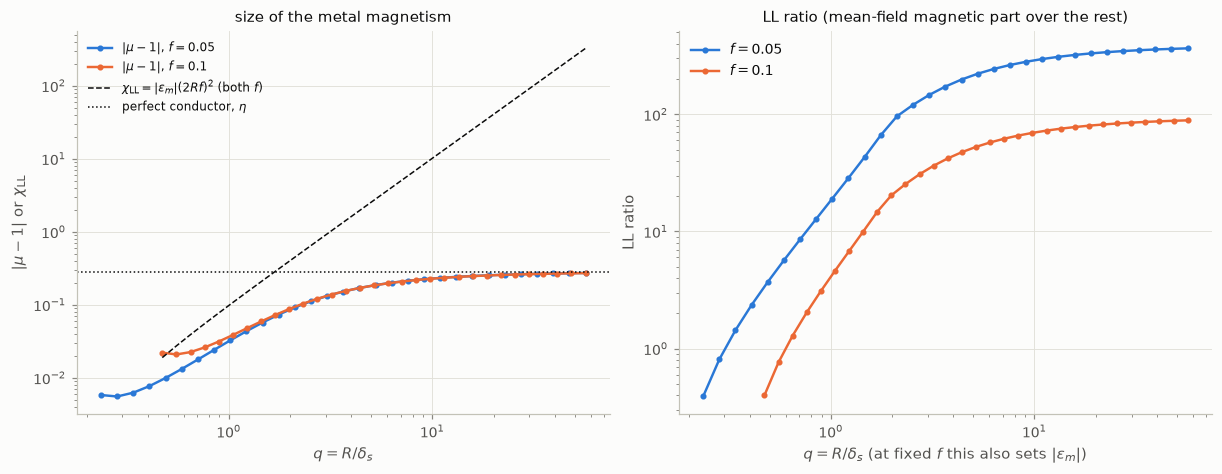

In [9]:
def ll_row(f, a_lp, rho=0.2, M=5, s_ratio=None):
    eps = drude(f, a_lp)
    c = te_coefficients(f, eps, rho=rho, M=M)
    K = k2(f)
    mob = mu_obp(f, eps).real
    tau_mag = (1 - 1 / mob) / K
    rest = max(abs(c["delta"].real), abs(c["lam"].real), abs(c["tau"].real - tau_mag))
    return dict(f=f, a_lp=a_lp, q=q_of(a_lp), eps=eps.real, ktau=(K * c["tau"]).real, mu=1 / (1 - (K * c["tau"]).real),
                mu_obp=mob, delta=c["delta"].real, lam=c["lam"].real, rest=rest, tau_mag=tau_mag, ll=abs(tau_mag) / rest,
                chi_ll=abs(eps) * (2 * R * f) ** 2)


t0 = time.perf_counter()
scan = {f: [ll_row(f, a) for a in np.logspace(np.log10(2.5 * f), np.log10(30), 31)] for f in (0.05, 0.1)}
print(f"scan: {time.perf_counter() - t0:.0f} s")
col = lambda rows, k: np.array([r[k] for r in rows])
print("       a/lp       q     eps_m     |mu - 1|   |mu_OBP - 1|   chi_LL     LL ratio")
for f, rows in scan.items():
    print(f"f = {f}")
    for r in rows[::3]:
        print(f"   {r['a_lp']:7.3f} {r['q']:8.3f} {r['eps']:9.1f} {abs(r['mu'] - 1):11.5f} {abs(r['mu_obp'] - 1):12.5f} {r['chi_ll']:10.4f} {r['ll']:10.1f}")
assert abs(scan[0.05][-1]["chi_ll"] / scan[0.1][-1]["chi_ll"] - 1) < 1e-3        # chi_LL is a function of q alone (to the |eps_m| - 1 against |eps_m| difference)
for f, rows in scan.items():
    keep = col(rows, "a_lp") >= 5 * f                           # eps_m <= -24; closer to the dipole plasmon the other coefficients dominate tau
    dm = np.abs(col(rows, "mu") - 1)[keep]
    assert (np.diff(dm) > 0).all()                             # |mu - 1| increases with a/lambda_p at fixed frequency

# half of the saturated value
sat = FILL                                                      # |mu - 1| for a perfect conductor, mu = 1 - eta (section 2c)
half = {}
for f, rows in scan.items():
    dm, qv = np.abs(col(rows, "mu") - 1), col(rows, "q")
    half[f] = np.exp(np.interp(sat / 2, dm, np.log(qv)))
q_half_london = brentq(lambda qq: mu_london(qq) - 0.5, 0.5, 20)
print(f"|mu - 1| = eta / 2 (half of the perfect-conductor value eta = {sat:.4f}) at q = {half[0.1]:.3f} (a/lambda_p = {half[0.1] / (TWO_PI * R):.3f}) for f = 0.1,"
      f" q = {half[0.05]:.3f} for f = 0.05")
print(f"mean-field estimate in the static limit: mu_rod = 1/2 at q = {q_half_london:.3f}; |mu_OBP - 1| = eta / 2 at the q where mu_rod = 1/2")
check("half-saturation at f = 0.1 against the one-rod value (q)", half[0.1], 0.35, q_half_london)
big_q = scan[0.1][-1]
print(f"at the largest a/lambda_p = {big_q['a_lp']:.0f} and f = 0.1: |mu - 1| = {abs(big_q['mu'] - 1):.4f}, perfect conductor eta = {sat:.4f}")
check("large q, f = 0.1: |mu - 1| within 5 percent of the perfect-conductor value", abs(big_q["mu"] - 1) / sat - 1, 0.05)

# the LL estimate against the response
over = [abs(r["mu"] - 1) / r["chi_ll"] for r in scan[0.1]]
assert over[-1] < 0.05 * over[0]                                   # the estimate keeps growing like |eps_m|, the response saturates
print(f"|mu - 1| / chi_LL falls from {over[0]:.3f} at a/lambda_p = {scan[0.1][0]['a_lp']:.2f} to {over[-1]:.4f} at {scan[0.1][-1]['a_lp']:.0f} (f = 0.1)")

print("\nLL ratio at a/lambda_p = 0.1, 1, 10 (- : eps_m above -5 there, near the electric dipole plasmon of the rods or not metallic)")
print("      f   a/lp = 0.1      1       10")
ll_table = {}
for f in (0.01, 0.02, 0.05, 0.1):
    cells = []
    for a in (0.1, 1.0, 10.0):
        if a < 2.5 * f:
            cells.append("   -   ")
            continue
        r = ll_row(f, a)
        ll_table[(f, a)] = r["ll"]
        cells.append(f"{r['ll']:9.1f}")
    print(f"  {f:5.2f}  " + " ".join(cells))
assert ll_table[(0.1, 10.0)] < ll_table[(0.05, 10.0)] < ll_table[(0.02, 10.0)]
check("large q: the LL ratio falls like 1 / f^2 (ratio at f = 0.05 over f = 0.1, a/lambda_p = 10, against 4; a consequence of the definition, section 5)", ll_table[(0.05, 10.0)] / ll_table[(0.1, 10.0)], 0.3, 4.0)
check("... and at f = 0.01 over f = 0.02 (against 4)", ll_table[(0.01, 10.0)] / ll_table[(0.02, 10.0)], 0.3, 4.0)
assert ll_table[(0.02, 1.0)] > ll_table[(0.02, 0.1)]               # at fixed frequency the ratio grows with a/lambda_p

# thin rods: the ratio is set by |eps_m|, not by the size. q = 2 pi R a/lambda_p = 2 pi R f sqrt(1 + |eps_m|); q << 1 for all rows
print("\nthin rods (q << 1) at fixed |eps_m|, two sizes: LL ratio, LL / |eps_m|, and the same ratio for a dielectric rod of the same |eps| (loop numerator of notebook 03)")
print("  |eps_m|   f       a/lp        q     LL ratio   LL / |eps_m|   dielectric rod, eps_r = |eps_m|")
thin = {}
for e_abs in (15.0, 100.0, 1000.0):
    for f_t in (1e-3, 1e-2):
        r = ll_row(f_t, f_t * np.sqrt(1 + e_abs))
        cd = te_coefficients(f_t, e_abs, rho=0.2, M=5)
        loop = FILL * (e_abs - 1) * R**2 / 8
        ll_d = loop / max(abs(cd["delta"].real), abs(cd["lam"].real), abs(cd["tau"].real - loop))
        thin[(e_abs, f_t)] = (r["ll"], ll_d)
        print(f"  {e_abs:7.0f} {f_t:6.0e} {r['a_lp']:9.4f} {r['q']:8.3f} {r['ll']:10.1f} {r['ll'] / e_abs:13.3f} {ll_d:16.1f}")
        assert r["q"] < 1
for e_abs in (15.0, 100.0, 1000.0):
    check(f"thin rods, |eps_m| = {e_abs:.0f}: the LL ratio does not depend on the size (f = 1e-2 over 1e-3, minus 1)", thin[(e_abs, 1e-2)][0] / thin[(e_abs, 1e-3)][0] - 1, 0.03)
    assert 0.10 < thin[(e_abs, 1e-3)][0] / e_abs < 0.20             # LL is about 0.16 |eps_m| ...
    assert 0.5 < thin[(e_abs, 1e-3)][0] / thin[(e_abs, 1e-3)][1] < 2     # ... as for a dielectric rod of the same |eps|, to a factor of two
assert thin[(15.0, 1e-3)][0] < 3 and thin[(1000.0, 1e-3)][0] > 100   # order one only for |eps_m| <~ 15

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
for i, (f, rows) in enumerate(scan.items()):
    qv = col(rows, "q")
    axs[0].loglog(qv, np.abs(col(rows, "mu") - 1), "o-", ms=3, color=CAT[i], label=rf"$|\mu-1|$, $f={f}$")
    if f == 0.1:
        axs[0].loglog(qv, col(rows, "chi_ll"), color=INK, ls="--", lw=1, label=r"$\chi_{\rm LL}=|\varepsilon_m|(2Rf)^2$ (both $f$)")
    axs[1].loglog(qv, col(rows, "ll"), "o-", ms=3, color=CAT[i], label=rf"$f={f}$")
axs[0].axhline(sat, color=INK, ls=":", lw=1, label=r"perfect conductor, $\eta$")
axs[0].set(xlabel=r"$q=R/\delta_s$", ylabel=r"$|\mu-1|$ or $\chi_{\rm LL}$", title=r"size of the metal magnetism"); axs[0].legend(loc="upper left", fontsize=8)
axs[1].set(xlabel=r"$q=R/\delta_s$ (at fixed $f$ this also sets $|\varepsilon_m|$)", ylabel="LL ratio", title="LL ratio (mean-field magnetic part over the rest)"); axs[1].legend()
plt.show()

Where the metal is thin compared with the skin depth, $|\mu-1|$ rises like $q^2$ and the LL estimate $\chi\sim|\varepsilon_m|(l/\lambda_0)^2$ is of the right order of magnitude (the next cell gives its ratio to the response, about two). Beyond $q\approx1$ the response bends over and saturates at the flux-exclusion value $\eta$, reaching half of it at the printed $q$, which is close to the $q$ at which the one-rod $\mu_{\rm rod}$ is one half; the lattice at $f=0.1$ and $0.05$ follows the static one-rod curve there (which, by section 2b, is the exact static limit and not only a model). The estimate keeps growing in proportion to $|\varepsilon_m|$ and overstates the magnetism of thick rods by orders of magnitude, because a field cannot be expelled from more than the area of the rods. Close to the electric-dipole plasmon (the first rows) $|\mu-1|$ from $\tau$ is not even monotonic in $a/\lambda_p$: there the other second-order coefficients are large (the first rows of the table show the LL ratio below one and $|\mu-1|$ well above $|\mu_{\rm OBP}-1|$ as $\varepsilon_m$ approaches the plasmon), and it is not the magnetic part that $\tau$ reports.

The LL ratio reads the same curves another way. At fixed frequency it grows with $a/\lambda_p$ (the printed table) and saturates, because the numerator saturates at order one while the denominator is a geometric constant of the lattice times $k_0^2$. At large $q$ the ratio then falls like $1/f^2$, and the check after the table confirms the factor between neighboring frequencies; this decay is simply that of a frequency-independent $k_0^2\tau_{\rm mag}$ against geometric coefficients that scale as $(k_0a)^2$. It follows from the definition and is not specific to metals: section 5 runs a rod with a true static permeability through the same ratio and finds the same law with a similar size. In the printed table the magnetic part exceeds the rest by a factor of order ten to a hundred or more at $f=0.05$ to $0.1$ for $a/\lambda_p=1$ to $10$.

**Thin rods.** For thin rods the ratio is not a function of the size at all, and not of $q$ either, although the right-hand panel of the figure plots it against $q$: at fixed $f$ the abscissa also fixes the permittivity, $q=k_0R\sqrt{|\varepsilon_m|}$, so that small $q$ means small $|\varepsilon_m|$ and the panel shows a permittivity dependence. The thin-rod table prints this: at fixed $|\varepsilon_m|$ the ratio is the same at the two sizes, about $0.13$ to $0.16$ times $|\varepsilon_m|$, and the same, to within a factor of two, as for a dielectric rod of equal $|\varepsilon|$ (last column, notebook 03's loop numerator; the last row at $f=10^{-2}$ is a dielectric rod close to its resonance and not comparable), as expected since a thin metal rod, with a field that is nearly uniform inside it, is a dielectric with a negative permittivity. It is of order one only for $|\varepsilon_m|\lesssim15$, as for a noble metal in the visible, and printed as about 160 at $|\varepsilon_m|=1000$.

**What shrinking does.** A structure that is scaled down at fixed wavelength changes $a/\lambda_0=f$ and $a/\lambda_p$ in the same proportion and keeps $\varepsilon_m$ fixed. The next cell follows that path for $\varepsilon_m=-15$ ($\lambda_0/\lambda_p=4$, of the order of a noble metal in the visible).

fixed lambda_0 / lambda_p = 4.0, eps_m = -15: scaling the lattice down (f = a / lambda_0)
      f        q     |mu - 1|    chi_LL     LL ratio
   0.0040    0.030   4.602e-05  8.640e-05        1.9
   0.0063    0.048   1.153e-04  2.166e-04        1.9
   0.0100    0.076   2.889e-04  5.429e-04        1.9
   0.0159    0.120   7.229e-04  1.361e-03        1.9
   0.0251    0.189   1.804e-03  3.411e-03        1.9
   0.0398    0.300   4.474e-03  8.549e-03        1.9
   0.0630    0.475   1.092e-02  2.143e-02        1.9
   0.0997    0.752   2.567e-02  5.372e-02        2.0
   0.1579    1.191   5.529e-02  1.346e-01        2.2
   0.2500    1.885   9.806e-02  3.375e-01        1.5
exponent of |mu - 1| against the size a/lambda_0 over the four smallest: 1.998
PASS  shrinking at fixed permittivity: |mu - 1| falls like the square of the size: got 1.9981, target 2, |diff| 1.90e-03 <= 3e-02
|mu - 1| / chi_LL along the path: [0.533, 0.533, 0.532, 0.531, 0.529, 0.523, 0.51, 0.478, 0.411, 0.291] ; eta pi^2 / 8

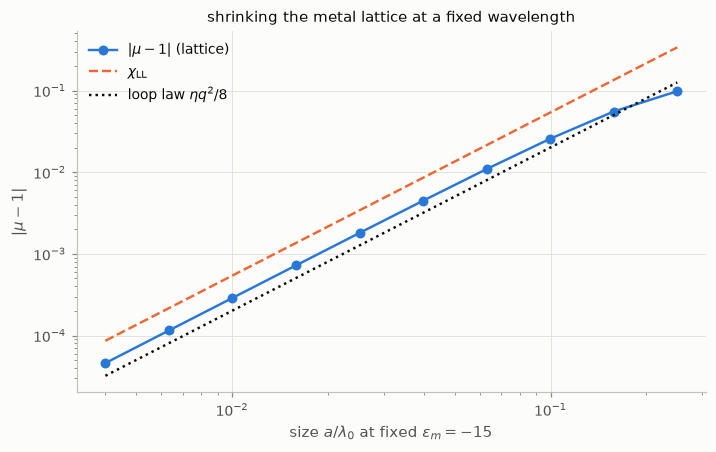

In [10]:
S_PATH = 4.0
FP = np.logspace(np.log10(0.004), np.log10(0.25), 10)
path = [ll_row(f, S_PATH * f) for f in FP]
mu_m1 = np.abs(col(path, "mu") - 1)
print(f"fixed lambda_0 / lambda_p = {S_PATH}, eps_m = {1 - S_PATH**2:.0f}: scaling the lattice down (f = a / lambda_0)")
print("      f        q     |mu - 1|    chi_LL     LL ratio")
for r, m in zip(path, mu_m1):
    print(f"  {r['f']:7.4f} {r['q']:8.3f} {m:11.3e} {r['chi_ll']:10.3e} {r['ll']:10.1f}")
sl = np.polyfit(np.log(FP[:4]), np.log(mu_m1[:4]), 1)[0]
print(f"exponent of |mu - 1| against the size a/lambda_0 over the four smallest: {sl:.3f}")
check("shrinking at fixed permittivity: |mu - 1| falls like the square of the size", sl, 0.03, 2.0)
ratio_path = mu_m1 / col(path, "chi_ll")
print("|mu - 1| / chi_LL along the path:", np.round(ratio_path, 3).tolist(), f"; eta pi^2 / 8 = {FILL * np.pi**2 / 8:.3f}")
assert 0.3 < ratio_path[0] < 0.8                                    # the LL estimate is a factor of about two above the response
ll_path = col(path, "ll")
print(f"LL ratio over the four smallest sizes: {np.round(ll_path[:4], 1).tolist()}; at the largest size: {ll_path[-1]:.1f}")
check("... while the LL ratio does not change (relative spread over the four smallest)", (ll_path[:4].max() - ll_path[:4].min()) / ll_path[:4].mean(), 0.05)
assert ll_path[-1] < ll_path[0] and (ll_path > 1).all() and (ll_path < 3).all()

fig, ax = plt.subplots()
ax.loglog(FP, mu_m1, "o-", color=CAT[0], label=r"$|\mu-1|$ (lattice)")
ax.loglog(FP, col(path, "chi_ll"), "--", color=CAT[1], label=r"$\chi_{\rm LL}$")
ax.loglog(FP, FILL * col(path, "q")**2 / 8, ":", color=INK, label=r"loop law $\eta q^2/8$")
ax.set(xlabel=r"size $a/\lambda_0$ at fixed $\varepsilon_m=-15$", ylabel=r"$|\mu-1|$", title="shrinking the metal lattice at a fixed wavelength"); ax.legend()
plt.show()

At fixed permittivity the magnetism falls with size like $q^2$, that is like $a^2$: the printed exponent. The LL ratio does not change with size. In the thin-rod regime $k_0^2\tau_{\rm mag}\approx-\eta q^2/8=-\eta k_0^2R^2|\varepsilon_m|/8$, so that $\tau_{\rm mag}$ in units of $a^2$ depends on $\varepsilon_m$ and $R$ and not on the frequency, and the other coefficients are fixed by the geometry (notebook 03: they hardly change with frequency far from a resonance); the ratio is then a function of $\varepsilon_m$ alone. For $\varepsilon_m=-15$ it is about two at every size (the printed row, which also bounds it between one and three), and it falls where retardation sets in at the largest sizes. The ratio of the loop-law size to the other terms is therefore set by the material, through $|\varepsilon_m|$ and a geometric factor (about $0.13$ to $0.16$ times $|\varepsilon_m|$ for thin rods, thin-rod table above), and not by the size of the structure.

The statement for this lattice, stated as such: for rods thinner than the skin depth the magnetic part of the second-order response is proportional to $q^2$ at fixed $\varepsilon_m$, shrinks with the square of the size, and is a small multiple of the rest of the second-order response at $|\varepsilon_m|\approx15$ (loss is not included in this path); at larger $|\varepsilon_m|$ the ratio of thin rods rises in proportion to $|\varepsilon_m|$, as for a dielectric. It becomes large compared with the rest for thick rods, where the response is flux exclusion with a value of order $\eta$ that is a property of the area filling and not of a resonance. What is specific to metals here is the sign of the loop response (diamagnetic, from the negative $\varepsilon_m$) and the saturation at $|\mu-1|\le\eta$; the $q^2$ law at fixed $\varepsilon_m$ is the loop law of a dielectric with a negative permittivity (thin-rod table). The $1/f^2$ decay of the ratio is not specific: it holds equally for a rod with a true permeability (section 5), because it follows from the definition of the ratio, and it is therefore no evidence for the Landau-Lifshitz mechanism, in which the susceptibility of the material itself vanishes at high frequency.

## 5. A true permeability as a control

A rod with $\mu_r\neq1$ has the same static response as the metal in the other direction: in a static field $H_z$ is continuous, so the induction averaged over the cell is $[1+\eta(\mu_r-1)]H$, and

$$k_0^2\tau\to1-\frac1{1+\eta(\mu_r-1)}\qquad(f\to0),$$

whatever the permittivity of the rod. It is the same formula as the flux exclusion of the perfect conductor ($\mu_r=0$). `basislattice.driven` handles $\mu_r\neq1$ in TE (it was checked in its own validation against plane waves in TE with $\mu_r=3$ at $f=0.1$ and $0.2$, agreeing to $2\times10^{-4}$ after extrapolation in the plane-wave basis size, and the check below adds the static limit with the Cauchy-integral coefficients of this notebook; TM with $\mu_r\ne1$ is not implemented). The first cell confirms that with one rod per cell it returns what `rodlattice` does.

In [11]:
def te_coefficients_basis(f, rods, rho=0.2, M=4):
    """k0-independent coefficients tau, delta, lambda of a lattice with a basis (basislattice.driven), as te_coefficients."""
    k0 = TWO_PI * f

    def parts(kap, phi):
        kh = np.array([np.cos(phi), np.sin(phi)])
        th = np.array([-kh[1], kh[0]])
        e = bl.driven(k0, kap * kh, rods, "TE", M=M)[0]
        return np.array([th @ e @ th, kh @ e @ kh, th @ e @ kh])

    cX, cM = taylor(lambda kap: parts(kap, 0.0), rho), taylor(lambda kap: parts(kap, np.pi / 4), rho)
    return dict(eps=cX[0, 0], tau=0.5 * (cX[2, 0] + cM[2, 0]), delta=0.5 * (cM[2, 0] - cX[2, 0]), lam=0.5 * (cX[2, 1] + cM[2, 1]))


c_rl = te_coefficients(0.1, 12.0, rho=0.2, M=4)
c_bl = te_coefficients_basis(0.1, [bl.Rod((0.0, 0.0), R, 12.0)], rho=0.2, M=4)
check("basislattice with one dielectric rod per cell against rodlattice (tau, relative)", c_bl["tau"] / c_rl["tau"] - 1, 1e-10)
c_rl = te_coefficients(0.1, drude(0.1, 3.0, 1 / 300), rho=0.2, M=4)
c_bl = te_coefficients_basis(0.1, [bl.Rod((0.0, 0.0), R, drude(0.1, 3.0, 1 / 300))], rho=0.2, M=4)
check("... and with a lossy Drude rod (tau, relative)", c_bl["tau"] / c_rl["tau"] - 1, 1e-10)

F_MAG = 1e-3
print(f"magnetic rods, f = {F_MAG}: k0^2 tau against 1 - 1/(1 + eta (mu_r - 1))")
print("   eps_r   mu_r   k0^2 tau      static formula    difference")
mag_vals = {}
for eps_r, mu_r in ((1.0, 5.0), (4.0, 5.0), (1.0, 2.0), (4.0, 0.5), (1.0, 0.0001)):
    c = te_coefficients_basis(F_MAG, [bl.Rod((0.0, 0.0), R, eps_r, mu_r)])
    kt = (k2(F_MAG) * c["tau"]).real
    form = 1 - 1 / (1 + FILL * (mu_r - 1))
    mag_vals[(eps_r, mu_r)] = kt
    print(f"  {eps_r:6.1f} {mu_r:6.4f} {kt:12.6f} {form:15.6f} {kt - form:12.2e}")
    check(f"eps_r = {eps_r}, mu_r = {mu_r}: k0^2 tau against the static formula", kt, 1e-4, form)
print(f"the perfect-conductor value 1 - 1/(1 - eta) = {1 - 1 / (1 - FILL):.6f} is the mu_r -> 0 case of the same formula")
magf = [(k2(f) * te_coefficients_basis(f, [bl.Rod((0.0, 0.0), R, 1.0, 5.0)])["tau"]).real for f in (1e-3, 2e-3, 4e-3)]
print("mu_r = 5, eps_r = 1: k0^2 tau at f = 1e-3, 2e-3, 4e-3:", np.round(magf, 6).tolist())
check("magnetic rod: k0^2 tau is frequency independent (f = 4e-3 over 1e-3, minus 1)", magf[2] / magf[0] - 1, 1e-3)
assert mag_vals[(1.0, 5.0)] > 0 > mag_vals[(4.0, 0.5)]

# the LL ratio of section 4 for a rod with a true permeability: same definition, tau_mag from the exact static mu of the magnetic rod
def ll_magnetic(f, eps_r, mu_r):
    c = te_coefficients_basis(f, [bl.Rod((0.0, 0.0), R, eps_r, mu_r)])
    tm = (1 - 1 / (1 + FILL * (mu_r - 1))) / k2(f)
    rest = max(abs(c["delta"].real), abs(c["lam"].real), abs(c["tau"].real - tm))
    return abs(tm) / rest, c["tau"].real - tm


FS_LL = (0.01, 0.02, 0.05, 0.1)
ll_ctrl = {key: [ll_magnetic(f, *key) for f in FS_LL] for key in ((1.0, 0.01), (4.0, 0.5))}
ll_metal = [ll_row(f, 10.0) for f in FS_LL]
print("\nLL ratio of section 4, same definition, for rods with a true permeability and for the metal rod at a/lambda_p = 10 (q = 18.8)")
print("                                   f = 0.01       0.02       0.05        0.1")
for key, v in ll_ctrl.items():
    print(f"  eps_r = {key[0]}, mu_r = {key[1]:5.2f}   " + " ".join(f"{x[0]:10.1f}" for x in v))
print(f"  metal, a/lambda_p = 10             " + " ".join(f"{r['ll']:10.1f}" for r in ll_metal))
for key, v in ll_ctrl.items():
    check(f"magnetic control rod {key}: the LL ratio falls like 1 / f^2 (f = 0.01 over 0.02, against 4)", v[0][0] / v[1][0], 0.3, 4.0)
    assert 0.3 < v[0][0] / ll_metal[0]["ll"] < 3 and 0.3 < v[3][0] / ll_metal[3]["ll"] < 3     # the same size as the metal rod
print(f"tau - tau_mag at f = 0.01 (units of a^2): mu_r = 0.01 rod {ll_ctrl[(1.0, 0.01)][0][1]:.5f}, metal at a/lambda_p = 10 {ll_metal[0]['ktau'] / k2(0.01) - ll_metal[0]['tau_mag']:.5f}; eta R^2 / 8 = {FILL * R**2 / 8:.5f}")
check("tau - tau_mag of the metal rod equals that of the mu_r = 0.01 rod (units of a^2): it is a magnetic finite-frequency correction, not a non-magnetic one",
      ll_metal[0]["ktau"] / k2(0.01) - ll_metal[0]["tau_mag"], 1e-4, ll_ctrl[(1.0, 0.01)][0][1])

PASS  basislattice with one dielectric rod per cell against rodlattice (tau, relative): got 0+1.95587e-30j, target 0, |diff| 1.96e-30 <= 1e-10
PASS  ... and with a lossy Drude rod (tau, relative): got 0-3.84268e-19j, target 0, |diff| 3.84e-19 <= 1e-10
magnetic rods, f = 0.001: k0^2 tau against 1 - 1/(1 + eta (mu_r - 1))
   eps_r   mu_r   k0^2 tau      static formula    difference
     1.0 5.0000     0.530731        0.530731     5.04e-07
PASS  eps_r = 1.0, mu_r = 5.0: k0^2 tau against the static formula: got 0.530731, target 0.530731, |diff| 5.04e-07 <= 1e-04
     4.0 5.0000     0.530733        0.530731     1.82e-06
PASS  eps_r = 4.0, mu_r = 5.0: k0^2 tau against the static formula: got 0.530733, target 0.530731, |diff| 1.82e-06 <= 1e-04
     1.0 2.0000     0.220421        0.220421     8.69e-08
PASS  eps_r = 1.0, mu_r = 2.0: k0^2 tau against the static formula: got 0.220421, target 0.220421, |diff| 8.69e-08 <= 1e-04


     4.0 0.5000    -0.164648       -0.164648     6.04e-08
PASS  eps_r = 4.0, mu_r = 0.5: k0^2 tau against the static formula: got -0.164648, target -0.164648, |diff| 6.04e-08 <= 1e-04
     1.0 0.0001    -0.394146       -0.394146     2.78e-07
PASS  eps_r = 1.0, mu_r = 0.0001: k0^2 tau against the static formula: got -0.394146, target -0.394146, |diff| 2.78e-07 <= 1e-04
the perfect-conductor value 1 - 1/(1 - eta) = -0.394201 is the mu_r -> 0 case of the same formula
mu_r = 5, eps_r = 1: k0^2 tau at f = 1e-3, 2e-3, 4e-3: [0.530731, 0.530733, 0.530739]
PASS  magnetic rod: k0^2 tau is frequency independent (f = 4e-3 over 1e-3, minus 1): got 1.42468e-05, target 0, |diff| 1.42e-05 <= 1e-03



LL ratio of section 4, same definition, for rods with a true permeability and for the metal rod at a/lambda_p = 10 (q = 18.8)
                                   f = 0.01       0.02       0.05        0.1
  eps_r = 1.0, mu_r =  0.01      14375.1     3593.6      574.8      143.5
  eps_r = 4.0, mu_r =  0.50      15211.1     3798.5      603.0      146.5
  metal, a/lambda_p = 10                 8352.8     2085.6      330.8       80.2
PASS  magnetic control rod (1.0, 0.01): the LL ratio falls like 1 / f^2 (f = 0.01 over 0.02, against 4): got 4.00019, target 4, |diff| 1.87e-04 <= 3e-01
PASS  magnetic control rod (4.0, 0.5): the LL ratio falls like 1 / f^2 (f = 0.01 over 0.02, against 4): got 4.00452, target 4, |diff| 4.52e-03 <= 3e-01
tau - tau_mag at f = 0.01 (units of a^2): mu_r = 0.01 rod 0.00685, metal at a/lambda_p = 10 0.00685; eta R^2 / 8 = 0.00318
PASS  tau - tau_mag of the metal rod equals that of the mu_r = 0.01 rod (units of a^2): it is a magnetic finite-frequency correction, not a

The permittivity of the rod does not change the static value (compare the first two rows), and the sign follows $\mu_r-1$: a rod with $\mu_r<1$ is diamagnetic in the same way a metal is.

**Four classes.** The next cell computes $k_0^2\tau$ at two frequencies for one rod of each kind and states, for each, what the second-order term does as $f\to0$. "Permeability in the static sense" is read as: $k_0^2\tau$ tends to a nonzero constant, so that $\mu\ne1$ at zero frequency.

In [12]:
classes = [
    ("dielectric rod, eps_r = 12", lambda f: te_coefficients(f, 12.0)["tau"], 0.0),
    ("plasma metal, a/lambda_p = 3", lambda f: te_coefficients(f, drude(f, 3.0))["tau"], 1 - 1 / mu_obp(1e-6, drude(1e-6, 3.0)).real),
    ("ohmic metal, a/lambda_p = 3, f_gamma/f_p = 1/30", lambda f: te_coefficients(f, drude(f, 3.0, 1 / 30))["tau"], 0.0),
    ("magnetic rod, mu_r = 5, eps_r = 1", lambda f: te_coefficients_basis(f, [bl.Rod((0.0, 0.0), R, 1.0, 5.0)])["tau"], 1 - 1 / (1 + 4 * FILL)),
]
print("class                                              f = 1e-4          f = 1e-5        exponent (re / im)     static limit")
tab = {}
for name, fun, limit in classes:
    v4, v5 = k2(1e-4) * fun(1e-4), k2(1e-5) * fun(1e-5)
    e_re = np.log(abs(v4.real) / abs(v5.real)) / np.log(10)
    e_im = np.log(abs(v4.imag) / abs(v5.imag)) / np.log(10) if abs(v4.imag) > 1e-7 * abs(v4.real) else np.nan
    tab[name] = (v5, e_re, e_im, limit)
    print(f"{name:50s} {v4.real:+.3e}{v4.imag:+.1e}j {v5.real:+.3e}{v5.imag:+.1e}j   {e_re:+.2f} / " + ("  - " if np.isnan(e_im) else f"{e_im:+.2f}") + f"   {limit:+.5f}")
names = list(tab)
check("dielectric: exponent 2, static limit zero", tab[names[0]][1], 0.01, 2.0)
check("plasma metal: constant, equal to 1 - 1/mu_OBP (f = 1e-5)", tab[names[1]][0].real, 1e-6, tab[names[1]][3])
check("ohmic metal: real part exponent 2", tab[names[2]][1], 0.02, 2.0)
check("ohmic metal: imaginary part exponent 1", tab[names[2]][2], 0.02, 1.0)
check("magnetic rod: constant, equal to the static formula (f = 1e-5)", tab[names[3]][0].real, 1e-4, tab[names[3]][3])
check("ohmic metal: the static limit is zero (|k0^2 tau| at f = 1e-5, which is still linear in f and a thousandth of the plasma value)", abs(tab[names[2]][0]), 1e-3)
check("dielectric: the static limit is zero (|k0^2 tau| at f = 1e-5)", abs(tab[names[0]][0]), 1e-9)

class                                              f = 1e-4          f = 1e-5        exponent (re / im)     static limit
dielectric rod, eps_r = 12                         +9.018e-09+7.7e-18j +9.018e-11-8.8e-19j   +2.00 /   -    +0.00000
plasma metal, a/lambda_p = 3                       -2.377e-01+1.4e-10j -2.377e-01-4.8e-09j   -0.00 /   -    -0.23775
ohmic metal, a/lambda_p = 3, f_gamma/f_p = 1/30    -5.883e-06+1.1e-03j -5.883e-08+1.1e-04j   +2.00 / +1.00   +0.00000


magnetic rod, mu_r = 5, eps_r = 1                  +5.307e-01-6.7e-18j +5.307e-01-1.4e-17j   +0.00 /   -    +0.53073
PASS  dielectric: exponent 2, static limit zero: got 2, target 2, |diff| 7.66e-08 <= 1e-02
PASS  plasma metal: constant, equal to 1 - 1/mu_OBP (f = 1e-5): got -0.237745, target -0.237745, |diff| 3.38e-09 <= 1e-06
PASS  ohmic metal: real part exponent 2: got 2, target 2, |diff| 3.80e-06 <= 2e-02
PASS  ohmic metal: imaginary part exponent 1: got 0.999988, target 1, |diff| 1.20e-05 <= 2e-02
PASS  magnetic rod: constant, equal to the static formula (f = 1e-5): got 0.530731, target 0.530731, |diff| 5.04e-11 <= 1e-04
PASS  ohmic metal: the static limit is zero (|k0^2 tau| at f = 1e-5, which is still linear in f and a thousandth of the plasma value): got 0.000113018, target 0, |diff| 1.13e-04 <= 1e-03
PASS  dielectric: the static limit is zero (|k0^2 tau| at f = 1e-5): got 9.01793e-11, target 0, |diff| 9.02e-11 <= 1e-09


Each class has a different low-frequency law, and only two of the four have a static permeability. The dielectric rod and the ohmic metal rod have $k_0^2\tau\to0$: their $\mu\to1$ as $f\to0$ and the magnetic response is dynamical (a loop current that needs a changing flux; the dielectric rod's goes like $f^2$, the ohmic metal's like $f$ in the imaginary part). The plasma metal rod and the rod with a true permeability have $k_0^2\tau\to$ constant: $\mu\ne1$ at zero frequency, diamagnetic for the metal (London), either sign for a magnetic material. The ohmic metal crosses over to the plasma behavior above a frequency set by the ohmic skin depth against the rod radius, close to $f_\gamma$ only for thin rods (section 3). This is the notebook's answer to which second-order terms are a permeability in the static sense: those whose coefficient times $k_0^2$ has a nonzero limit, and the two cases found are a rod whose material has $\mu_r\ne1$, and a rod of collisionless (London) metal that screens a static field; a normal metal does not.

One caution on the word. A rod with $\mu_r\ne1$ has a static permeability the lattice shares with the material. A plasma metal rod has none in the material, since its $\mu_r$ is one, yet the lattice has one, because the rod's screening currents flow at all frequencies below the plasma frequency. The two give the same coefficient through the same formula (the perfect conductor is the $\mu_r\to0$ case, see the printed $\mu_r=10^{-4}$ row), and the lattice does not distinguish them.

## 6. TM: metal rods as a two-dimensional wire medium

With $\mathbf E$ along the rods the response is a scalar, $\varepsilon_{zz}(\omega,\mathbf k)$, and a metal rod is a wire. Thin wires in a lattice are the standard model of a plasma with a reduced plasma frequency, $\varepsilon_{zz}(\omega,0)=1-k_p^2/k_0^2$ with $k_p$ set by the inductance of the wire lattice, not by the metal. The cell starts with a check of the TM driven response with metal rods against a plane-wave expansion. For TM the field is continuous and so is its product with $\varepsilon$ in the Helmholtz equation $\nabla^2E_z+k_0^2\varepsilon E_z=\dots$, so the plane-wave solution converges cleanly, and no factorization rule is needed.

In [13]:
def pw_tm(k0, kv, eps, n, rad=R):
    """eps_zz(w, k) from a plane-wave solution of (|k + G|^2 - k0^2 eps(r)) E = i k0 J, E along the rods."""
    G, E = _fourier_matrix(n, rad, eps)
    i0 = len(G) // 2
    kg = np.asarray(kv, float)[None, :] + G
    A = np.diag((kg**2).sum(1)) - k0**2 * E
    rhs = np.zeros(len(G), complex)
    rhs[i0] = 1j * k0
    Ef = np.linalg.solve(A, rhs)
    return (E[i0] @ Ef) / Ef[i0]


print("TM, Drude rods, multiple scattering (M = 6) against plane waves: |PW / MS - 1| for n = 6, 10, 14, 18, 22, 26")
tm_pw = {}
for tag, f, a_lp, g, kv, rad in (("a", 0.10, 1.0, 1 / 30, (0.9, 0.4), 0.3), ("b", 0.05, 0.4, 1 / 30, (0.9, 0.4), 0.3),
                                 ("c", 0.10, 3.0, 1 / 300, (0.5, 0.2), 0.3), ("d", 0.05, 3.0, 1 / 300, (0.5, 0.2), 0.1)):
    eps, k0 = drude(f, a_lp, g), TWO_PI * f
    ms = rl.driven(k0, kv, rad, eps, "TM", M=6)[0]
    errs = [abs(pw_tm(k0, kv, eps, n, rad) / ms - 1) for n in (6, 10, 14, 18, 22, 26)]
    tm_pw[tag] = errs
    print(f"  ({tag}) R = {rad}, f = {f}, a/lambda_p = {a_lp}, eps_m = {eps.real:.1f}{eps.imag:+.1f}i: " + "  ".join(f"{e:.1e}" for e in errs))
for tag in "abcd":
    assert tm_pw[tag][-1] < tm_pw[tag][1] / 10 and all(np.diff(np.log(tm_pw[tag])) < 0)       # falls monotonically, about as 1/n^2
check("TM metal rods against plane waves, worst case at n = 26 (relative)", max(v[-1] for v in tm_pw.values()), 2e-4)

TM, Drude rods, multiple scattering (M = 6) against plane waves: |PW / MS - 1| for n = 6, 10, 14, 18, 22, 26


  (a) R = 0.3, f = 0.1, a/lambda_p = 1.0, eps_m = -89.0+30.0i: 3.0e-04  8.4e-05  3.0e-05  1.5e-05  8.3e-06  4.9e-06


  (b) R = 0.3, f = 0.05, a/lambda_p = 0.4, eps_m = -58.8+15.9i: 4.6e-05  1.3e-05  4.6e-06  2.2e-06  1.3e-06  7.5e-07


  (c) R = 0.3, f = 0.1, a/lambda_p = 3.0, eps_m = -890.1+89.1i: 3.5e-03  9.3e-04  3.3e-04  1.7e-04  9.3e-05  5.6e-05


  (d) R = 0.1, f = 0.05, a/lambda_p = 3.0, eps_m = -3460.5+692.3i: 5.7e-03  1.1e-03  4.1e-04  2.1e-04  1.2e-04  7.6e-05
PASS  TM metal rods against plane waves, worst case at n = 26 (relative): got 7.58209e-05, target 0, |diff| 7.58e-05 <= 2e-04


The two methods agree at the largest basis to better than a part in $10^4$ in all four cases (the printed errors and the check), with errors that fall monotonically as the plane-wave basis grows and that are larger for the larger $|\varepsilon_m|$. This is the independent test of `rodlattice.driven` with metal rods for TM, and it is much cleaner than the TE one of section 2a.

### 6a. The plasma wavenumber of thin wires

$k_p^2=k_0^2\,[1-\varepsilon_{zz}(\omega,0)]$, from the zeroth Taylor coefficient on the circle of complex $\kappa$ (the lattice has no pole at $\kappa=0$, but the solver does not accept $\mathbf k=0$ exactly). Rods of radius $R=0.05$ ($\eta=0.0079$), $f=10^{-3}$. Two limits are compared with it. Weak metal ($q\ll1$): the field is uniform in the rod and $\varepsilon_{zz}=1+\eta(\varepsilon_m-1)$, that is $k_p^2=\eta k_{pm}^2$ with $k_{pm}=2\pi a/\lambda_p$; when the wires are thin there is also the inductance of the wire lattice in series, which the thin-wire formula below gives, so that $1/k_p^2\approx1/(\eta k_{pm}^2)+S_0$ with $S_0=[\ln(a/2\pi R)+0.5275]/2\pi$ (an addition of a kinetic and a magnetic inductance). Perfect wire ($q\gg1$): the thin-wire formula $k_p^2=1/S_0=2\pi/[a^2(\ln(a/2\pi R)+0.5275)]$ (Belov et al.; the constant 0.5275 is a rounding of the square-lattice sum $c=\ln[4\pi^{3/2}/\Gamma(1/4)^2]=0.52734$, identified in closed form in notebook 07, and is compared below at a smaller radius).

In [14]:
def tm_coefficients(f, eps, rad, rho=0.2, M=4, n=16, phi=0.0):
    """eps_zz(w, 0), and the coefficient of kappa^2 (the Cauchy-integral Taylor coefficients) along the direction phi."""
    k0 = TWO_PI * f
    cs = taylor(lambda kap: np.array([rl.driven(k0, (kap * np.cos(phi), kap * np.sin(phi)), rad, eps, "TM", M=M)[0]]), rho, n)
    return cs[0, 0], cs[2, 0], np.abs(cs[1, 0]) + np.abs(cs[3, 0])


def S0_wire(rad):
    return (np.log(1 / (TWO_PI * rad)) + 0.5275) / TWO_PI


def kp2_of(f, eps, rad, **kw):
    e0, c2, odd = tm_coefficients(f, eps, rad, **kw)
    return (k2(f) * (1 - e0)).real, (k2(f) * c2).real, odd


RW = 0.05
etaw = np.pi * RW**2
A_TM = [0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0, 300.0]
tm_rows = []
print(f"R = {RW}: thin-wire value 1 / S_0 = {1 / S0_wire(RW):.4f}")
print("  a/lp       q     k_p^2     eta k_pm^2   1/(1/(eta k_pm^2) + S_0)    k0^2 beta")
for a in A_TM:
    kp2, kb, odd = kp2_of(1e-3, drude(1e-3, a), RW)
    kpm2 = etaw * (TWO_PI * a) ** 2
    tm_rows.append((a, q_of(a, RW), kp2, kb))
    print(f"{a:7.2f} {q_of(a, RW):8.3f} {kp2:9.5f} {kpm2:12.5f} {1 / (1 / kpm2 + S0_wire(RW)):20.5f} {kb:14.6f}")
kp2s = np.array([r[2] for r in tm_rows])
assert (np.diff(kp2s) > 0).all()
for a in (0.03, 0.1, 0.3):
    kp2, _, _ = kp2_of(1e-3, drude(1e-3, a), RW)
    kpm2 = etaw * (TWO_PI * a) ** 2
    check(f"weak metal, a/lambda_p = {a}: k_p^2 against 1 / (1 / (eta k_pm^2) + S_0) (relative)", kp2 / (1 / (1 / kpm2 + S0_wire(RW))) - 1, 5e-3)

# frequency independence of k_p^2
kp_f = [kp2_of(f, drude(f, 3.0), RW)[0] for f in (1e-3, 3e-3, 1e-2)]
print("k_p^2 at f = 1e-3, 3e-3, 1e-2 (a/lambda_p = 3):", np.round(kp_f, 5).tolist())
check("k_p^2 is frequency independent: eps_zz = 1 - k_p^2 / k0^2 (f = 1e-2 against 1e-3, relative)", kp_f[2] / kp_f[0] - 1, 1e-3)

# perfect-wire limit: extrapolate in 1 / q through the three largest sizes
big3 = [A_TM.index(v) for v in (30.0, 100.0, 300.0)]
qv3 = np.array([tm_rows[i][1] for i in big3])
fit_kp = np.linalg.solve(np.vander(1 / qv3, 3, increasing=True), kp2s[big3])
print(f"R = {RW}: k_p^2 extrapolated to q -> infinity (fit in 1/q through q = {qv3.round(0).tolist()}): {fit_kp[0]:.4f}; thin-wire formula {1 / S0_wire(RW):.4f}")
check("R = 0.05: extrapolated k_p^2 against the thin-wire formula (relative; the formula is the leading term in R)", fit_kp[0] * S0_wire(RW) - 1, 5e-3)

# the constant 0.5275 at a smaller radius
R_SMALL = 0.01
q2 = np.array([30.0, 60.0, 100.0])
kp_small = np.array([kp2_of(1e-3, drude(1e-3, qq / (TWO_PI * R_SMALL)), R_SMALL)[0] for qq in q2])
fit_s = np.linalg.solve(np.vander(1 / q2, 3, increasing=True), kp_small)
print(f"R = {R_SMALL}: k_p^2 at q = {q2.tolist()}: {np.round(kp_small, 5).tolist()}, extrapolated {fit_s[0]:.5f}, thin-wire {1 / S0_wire(R_SMALL):.5f}")
check("R = 0.01: extrapolated k_p^2 against the thin-wire formula with 0.5275 (relative; 5e-4 in k_p^2 is a resolution of about 0.002 in the constant)", fit_s[0] * S0_wire(R_SMALL) - 1, 5e-4)
from scipy.special import gamma as gamma_fn
C_EXACT = np.log(4 * np.pi**1.5 / gamma_fn(0.25) ** 2)           # notebook 07, section 1(c), recalled and compared there with the model
c_implied = TWO_PI / fit_s[0] - np.log(1 / (TWO_PI * R_SMALL))
print(f"constant implied by the lattice at R = {R_SMALL}: c = {c_implied:.5f}; ln[4 pi^(3/2) / Gamma(1/4)^2] = {C_EXACT:.5f}; Belov's rounding 0.5275")
check("R = 0.01: the constant implied by the lattice against ln[4 pi^(3/2) / Gamma(1/4)^2] (the remaining difference is the O(R^2) correction of notebook 07)", c_implied, 2e-3, C_EXACT)

R = 0.05: thin-wire value 1 / S_0 = 3.7281
  a/lp       q     k_p^2     eta k_pm^2   1/(1/(eta k_pm^2) + S_0)    k0^2 beta
   0.03    0.009   0.00028      0.00028              0.00028       0.000000
   0.10    0.031   0.00310      0.00310              0.00310       0.000000
   0.30    0.094   0.02767      0.02791              0.02770       0.000003
   1.00    0.314   0.28300      0.31006              0.28626       0.000288
   3.00    0.942   1.50241      2.79056              1.59596       0.007796
  10.00    3.142   3.02316     31.00628              3.32796       0.026148
  30.00    9.425   3.48317    279.05649              3.67896       0.029948
 100.00   31.416   3.64261   3100.62767              3.72363       0.031007
 300.00   94.248   3.68831  27905.64901              3.72761       0.031302
PASS  weak metal, a/lambda_p = 0.03: k_p^2 against 1 / (1 / (eta k_pm^2) + S_0) (relative): got -1.12698e-05, target 0, |diff| 1.13e-05 <= 5e-03
PASS  weak metal, a/lambda_p = 0.1: k_p^2 agains

$k_p^2$ is frequency independent to the printed accuracy in this regime (relative change $2\times10^{-5}$ from $f=10^{-3}$ to $10^{-2}$, corrections of order $k_0^2$), so $\varepsilon_{zz}=1-k_p^2/k_0^2$ holds there. It rises from the diluted-metal value, $\eta k_{pm}^2$, at weak metal, through a region where the series combination of the printed column describes it (checked for $a/\lambda_p\le0.3$; departures of about 1, 6 and 10 percent at $a/\lambda_p=1$, 3 and 10), and saturates at the perfect-wire value: the lattice sets the plasma frequency of a wire medium once the wires are thicker than the skin depth, whatever the metal. The saturation is approached like $1/q$ (a correction of the order of the skin depth over the radius), and the extrapolated value agrees with the thin-wire formula; the constant in the thin-wire formula comes from a lattice sum of the square lattice; at a radius five times smaller the lattice implies the printed value of $c$, which agrees with the closed form $\ln[4\pi^{3/2}/\Gamma(1/4)^2]=0.52734$ of notebook 07 (Belov's 0.5275 is a rounding of it) to about $3\times10^{-4}$, a difference that is of the order of the corrections of higher order in $R$ and that the check, with its tolerance of 0.002, cannot attribute to the difference between the two constants.

### 6b. The $k^2$ coefficient and the in-plane permeability

The coefficient $\beta$ of $k^2$ in $\varepsilon_{zz}$ is isotropic for a square lattice (the next anisotropic term is of fourth order). Its combination $\mu_\parallel\equiv1/(1-k_0^2\beta)$ has the form of a permeability for the in-plane field at $\beta=0$ (notebook 01: with $\mathbf E$ along the axis the $k_\perp^2$ term has the form of a permeability), and it is used below as a label for the coefficient. It is not by itself a permeability: notebook 07 concludes, for the same structure, that the $k_\perp^2$ coefficient produced by the axial wire currents is non-magnetic spatial dispersion, and that only the flux-exclusion part (the $m=\pm1$ response of the rod) is magnetic. 2D Maxwell Garnett is the permeability of rods that carry no net axial current, so it is a prediction for that magnetic part and not a like-for-like comparison for the whole coefficient; the cells below separate the two. For perfect conductors in a transverse field, 2D Maxwell Garnett gives the number to compare with. Derivation: in statics the in-plane $\mathbf H$ outside perfectly conducting cylinders is curl-free with no flux through the rods, which is the electrostatics of cylinders with $\varepsilon=0$ for the potential problem $\nabla\cdot(\mu\nabla\psi)=0$, so $\mu_{\rm eff}=\mu_h(1+\eta B)/(1-\eta B)$ with $B=(\mu_i-\mu_h)/(\mu_i+\mu_h)=-1$, that is $\mu_{\rm MG}=(1-\eta)/(1+\eta)$. The static array, with Rayleigh's series for the square array as a more accurate value, is the same problem at higher order in $\eta$.

For wires, though, there is a second candidate. Each wire carries a net current, which Maxwell Garnett leaves out (its $\mathbf H$ is curl-free with no net circulation), and in a lattice that current has an inductance that depends on the Bloch phase. A model that keeps only this: a thin PEC wire carrying a uniform surface current, with the sum over the square lattice of the fields of the other wires, gives $\varepsilon_{zz}(\omega,\kappa)=1-1/[k_0^2A\,S(\kappa)]$ with $A=a^2$ and

$$S(\kappa)=S_0+\frac1A\sum_{\mathbf G\ne0}J_0(|\mathbf G|R)\Big[\frac1{|\boldsymbol\kappa+\mathbf G|^2}-\frac1{|\mathbf G|^2}\Big]\ \Rightarrow\ k_0^2\beta=\frac{s_2}{S_0^2},\quad s_2=\frac1A\sum_{\mathbf G\ne0}\frac{J_0(|\mathbf G|R)}{|\mathbf G|^4}.$$

(The sum over the square lattice of $[4(\boldsymbol\kappa\cdot\mathbf G)^2-\kappa^2G^2]/G^6$ averages to $\kappa^2/G^4$; the macroscopic $\mathbf G=0$ term cancels in the elimination of the wire current.) The model has the sign of $\beta$ and the units right by construction, and it contains no flux exclusion. The cell computes $k_0^2\beta$ from the lattice for the largest $q$ and compares it with the model for three small radii, then for $R=0.3$ with Maxwell Garnett.

perfectly conducting thin wires: k0^2 beta from the lattice (extrapolated in 1/q) against the model that keeps only the wire currents
      R      lattice     model    lattice / model


   0.010     0.01332   0.01400        0.952
   0.020     0.01944   0.02222        0.875
   0.050     0.03145   0.05003        0.629
PASS  R = 0.01: the lattice k0^2 beta against the wire-current model (ratio): got 0.951614, target 1, |diff| 4.84e-02 <= 1e-01
PASS  k0^2 beta is isotropic (Gamma-X against Gamma-M, relative; R = 0.05, a/lambda_p = 100): got -2.66908e-08, target 0, |diff| 2.67e-08 <= 1e-04
R = 0.3: static in-plane permeability of perfectly conducting cylinders, Maxwell Garnett 0.5592, Rayleigh's series 0.5585
        the corresponding k0^2 beta = 1 - 1/mu: -0.7884 and -0.7906
  q (R = 0.3)    k_p^2      k0^2 beta     mu_parallel = 1 / (1 - k0^2 beta)
         0.5     0.7585     0.000571             1.0006
         1.0     2.7561     0.006345             1.0064
         2.0     8.1855     0.030906             1.0319
         5.0    20.2567     0.000998             1.0010
        10.0    28.5509    -0.065623             0.9384
        30.0    35.9872    -0.121093            

       300.0    39.8250    -0.143066             0.8748


R = 0.3, perfect conductor (extrapolated in 1/q): k_p^2 = 40.268, k0^2 beta = -0.1452, mu_parallel = 0.8732
  Maxwell Garnett would give k0^2 beta = -0.7884 and mu = 0.5592; the lattice value is 0.18 of the first and the formal mu_parallel 0.873 against 0.559
  k_p a = 6.346 at R = 0.3 (the zone edge is pi): TM waves with k0 < k_p have k^2 = k0^2 - k_p^2(k) < 0 while k_p^2(k) rises with k, so mu_parallel is a formal Taylor coefficient that no propagating wave tests at subwavelength frequencies

k0^2 beta of perfectly conducting rods (extrapolated in 1/q) with the multipoles |m| <= M of the rods kept (M = 0 is the wire current alone)
  R = 0.3, M = 0: k0^2 beta = +11.8197
  R = 0.3, M = 1: k0^2 beta = -0.1631
  R = 0.3, M = 2: k0^2 beta = -0.1245
  R = 0.3, M = 4: k0^2 beta = -0.1452


  R = 0.3, M = 6: k0^2 beta = -0.1460
PASS  R = 0.3: the multipole truncation M = 4 used above against M = 6 (k0^2 beta): got -0.145205, target -0.146008, |diff| 8.03e-04 <= 2e-03
thin wires: the m = +-1 (dipole) correction beta(M = 1) - beta(M = 0) against the Maxwell-Garnett value, and the wire-current model against M = 0
  R = 0.01: M = 0 0.01416, model 0.01400; correction -0.00083, Maxwell Garnett -0.00063, ratio 1.33


  R = 0.05: M = 0 0.05784, model 0.05003; correction -0.02639, Maxwell Garnett -0.01583, ratio 1.67


floating rods (sigma = 1 / mu_r = 100), R = 0.3: sigma_eff from plane waves at n = 14, 20, 26: 1.8791, 1.8462, 1.8275; Rayleigh's series at this contrast 1.7688; sigma -> infinity limits: Rayleigh 1.7906, Maxwell Garnett 1.7884
  k0^2 beta (floating, n = 26) = -0.828; Rayleigh/Maxwell Garnett -0.791; grounded wires (the TM lattice, this notebook) -0.145
PASS  floating rods: the plane-wave sigma_eff at n = 26 against Rayleigh's series at the same contrast (relative; the error falls with n): got 0.0332037, target 0, |diff| 3.32e-02 <= 5e-02


R = 0.3, a/lambda_p = 30 (q = 57): k_p^2(kappa = 1.5) - k_p^2(kappa = 0.3): multiple scattering 0.27584; plane waves n = 10: 0.29478, n = 18: 0.28034, n = 26: 0.27755
  the offsets k_p^2(0.3) differ: MS 37.968, PW 39.687, 38.446, 38.162 (the plane-wave metal is not converged in absolute terms)
PASS  R = 0.3: the k dependence of k_p^2 from multiple scattering against plane waves (n = 26, relative): got 0.0062191, target 0, |diff| 6.22e-03 <= 2e-02


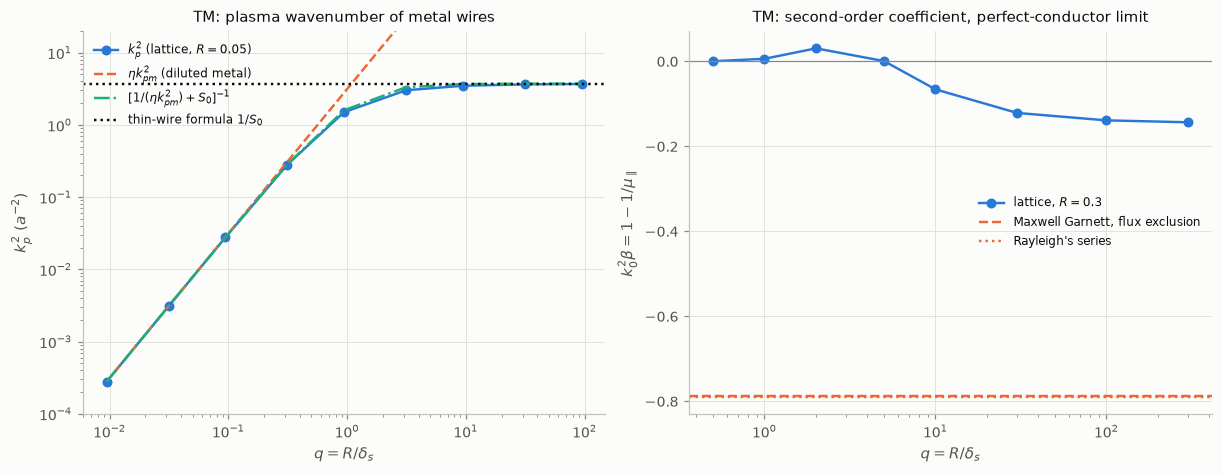

In [15]:
def s2_wire(rad, n=80):
    m = np.arange(-n, n + 1)
    mx, my = np.meshgrid(m, m, indexing="ij")
    g = TWO_PI * np.hypot(mx.ravel(), my.ravel())
    keep = g > 0
    from scipy.special import j0
    return (j0(g[keep] * rad) / g[keep] ** 4).sum()


def beta_pec(rad, qs=(30.0, 60.0, 100.0), **kw):
    """k0^2 beta extrapolated to q -> infinity (fit in 1/q) at f = 1e-3, rods of radius rad."""
    vals = np.array([kp2_of(1e-3, drude(1e-3, qq / (TWO_PI * rad)), rad, **kw)[1] for qq in qs])
    return np.linalg.solve(np.vander(1 / np.array(qs), len(qs), increasing=True), vals)[0], vals


print("perfectly conducting thin wires: k0^2 beta from the lattice (extrapolated in 1/q) against the model that keeps only the wire currents")
print("      R      lattice     model    lattice / model")
ratios = []
for rad in (0.01, 0.02, 0.05):
    bl_val, _ = beta_pec(rad)
    model = s2_wire(rad) / S0_wire(rad) ** 2
    ratios.append(bl_val / model)
    print(f"  {rad:6.3f} {bl_val:11.5f} {model:9.5f} {bl_val / model:12.3f}")
assert bl_val > 0 and all(np.diff(ratios) < 0)
check("R = 0.01: the lattice k0^2 beta against the wire-current model (ratio)", ratios[0], 0.1, 1.0)
assert ratios[0] > 0.9 and ratios[0] > ratios[1] > ratios[2]
b_x = kp2_of(1e-3, drude(1e-3, 100.0), RW, phi=0.0)[1]
b_m = kp2_of(1e-3, drude(1e-3, 100.0), RW, phi=np.pi / 4)[1]
check("k0^2 beta is isotropic (Gamma-X against Gamma-M, relative; R = 0.05, a/lambda_p = 100)", b_x / b_m - 1, 1e-4)

# R = 0.3: Maxwell Garnett and the lattice
mu_mg = (1 - FILL) / (1 + FILL)
b_r = -1.0
mu_ray = 1 + 2 * FILL / (1 / b_r - FILL - 0.305827 * b_r * FILL**4 - 0.013362 * b_r * FILL**8)
print(f"R = {R}: static in-plane permeability of perfectly conducting cylinders, Maxwell Garnett {mu_mg:.4f}, Rayleigh's series {mu_ray:.4f}")
print(f"        the corresponding k0^2 beta = 1 - 1/mu: {1 - 1 / mu_mg:.4f} and {1 - 1 / mu_ray:.4f}")
print("  q (R = 0.3)    k_p^2      k0^2 beta     mu_parallel = 1 / (1 - k0^2 beta)")
q_list = [0.5, 1.0, 2.0, 5.0, 10.0, 30.0, 100.0, 300.0]
tm3 = []
for qq in q_list:
    kp2, kb, _ = kp2_of(1e-3, drude(1e-3, qq / (TWO_PI * R)), R)
    tm3.append((qq, kp2, kb))
    print(f"  {qq:10.1f} {kp2:10.4f} {kb:12.6f} {1 / (1 - kb):18.4f}")
b_inf, b_vals = beta_pec(R, qs=(50.0, 100.0, 200.0))
kp_inf = np.linalg.solve(np.vander(1 / np.array([50.0, 100.0, 200.0]), 3, increasing=True), [kp2_of(1e-3, drude(1e-3, qq / (TWO_PI * R)), R)[0] for qq in (50.0, 100.0, 200.0)])[0]
print(f"R = {R}, perfect conductor (extrapolated in 1/q): k_p^2 = {kp_inf:.3f}, k0^2 beta = {b_inf:.4f}, mu_parallel = {1 / (1 - b_inf):.4f}")
print(f"  Maxwell Garnett would give k0^2 beta = {1 - 1 / mu_mg:.4f} and mu = {mu_mg:.4f}; the lattice value is {b_inf / (1 - 1 / mu_mg):.2f} of the first and the formal mu_parallel {1 / (1 - b_inf):.3f} against {mu_mg:.3f}")
print(f"  k_p a = {np.sqrt(kp_inf):.3f} at R = {R} (the zone edge is pi): TM waves with k0 < k_p have k^2 = k0^2 - k_p^2(k) < 0 while k_p^2(k) rises with k, so mu_parallel is a formal Taylor coefficient that no propagating wave tests at subwavelength frequencies")
assert np.sqrt(kp_inf) > np.pi
assert abs(b_inf) < 0.25 * abs(1 - 1 / mu_mg)                     # the lattice k0^2 beta is a quarter of the Maxwell-Garnett value or less
assert b_inf < 0 < ratios[0] and 1 / (1 - b_inf) > 0.8 and mu_mg < 0.6

# which part of beta is which: the rod multipoles |m| <= M kept in the lattice solver, perfect-conductor limit
print("\nk0^2 beta of perfectly conducting rods (extrapolated in 1/q) with the multipoles |m| <= M of the rods kept (M = 0 is the wire current alone)")
beta_M = {}
for Mx in (0, 1, 2, 4, 6):
    beta_M[Mx] = beta_pec(R, qs=(50.0, 100.0, 200.0), M=Mx)[0]
    print(f"  R = {R}, M = {Mx}: k0^2 beta = {beta_M[Mx]:+.4f}")
check("R = 0.3: the multipole truncation M = 4 used above against M = 6 (k0^2 beta)", beta_M[4], 2e-3, beta_M[6])
assert beta_M[0] > 5 and beta_M[6] < 0                        # the wire current alone is positive and large, the flux-exclusion terms overwhelm it
mg_thin = lambda rad: -2 * np.pi * rad**2 / (1 - np.pi * rad**2)       # Maxwell Garnett k0^2 beta = 1 - 1/mu_MG
print("thin wires: the m = +-1 (dipole) correction beta(M = 1) - beta(M = 0) against the Maxwell-Garnett value, and the wire-current model against M = 0")
dip = {}
for rad in (0.01, 0.05):
    b0, b1 = beta_pec(rad, M=0)[0], beta_pec(rad, M=1)[0]
    dip[rad] = (b1 - b0) / mg_thin(rad)
    print(f"  R = {rad}: M = 0 {b0:.5f}, model {s2_wire(rad) / S0_wire(rad)**2:.5f}; correction {b1 - b0:+.5f}, Maxwell Garnett {mg_thin(rad):+.5f}, ratio {dip[rad]:.2f}")
assert all(1.2 < v < 1.8 for v in dip.values())               # the dipole part is not the Maxwell-Garnett term even for thin wires (its field is that of the neighbors' wire currents)

# control: rods that carry no net axial current. In the quasi-static TM problem (k0 -> 0 at fixed k) E_z obeys -div(sigma grad E_z) = exp(ik.r)
# with sigma = 1 / mu_r inside the rods. A floating, current-free rod is sigma -> infinity (mu_r -> 0, eps_r = 1): E_z is constant in the rod and there is
# no net induced axial current, no plasma term. The effective sigma_eff = 1 / (k^2 psi_0) is 1 / mu_eff and k0^2 beta = 1 - sigma_eff. rodlattice has no TM mu_r, so
# this is a plane-wave solution of the static equation (the Laurent rule, as in pw_tm); its convergence in n is slow.
def sigma_eff_pw(sig, n, kv=(1e-2, 0.7e-2), rad=R):
    G, S = _fourier_matrix(n, rad, sig)
    i0 = len(G) // 2
    kg = np.asarray(kv, float)[None, :] + G
    rhs = np.zeros(len(G), complex)
    rhs[i0] = 1.0
    psi = np.linalg.solve((kg @ kg.T) * S, rhs)
    return (1 / (psi[i0] * (kv[0]**2 + kv[1]**2))).real


SIG = 100.0
bs = (SIG - 1) / (SIG + 1)
s_ray = 1 + 2 * FILL / (1 / bs - FILL - 0.305827 * bs * FILL**4 - 0.013362 * bs * FILL**8)       # Rayleigh's series, same contrast
s_float = [sigma_eff_pw(SIG, n) for n in (14, 20, 26)]
print(f"floating rods (sigma = 1 / mu_r = {SIG:.0f}), R = {R}: sigma_eff from plane waves at n = 14, 20, 26: " + ", ".join(f"{v:.4f}" for v in s_float)
      + f"; Rayleigh's series at this contrast {s_ray:.4f}; sigma -> infinity limits: Rayleigh {1 / mu_ray:.4f}, Maxwell Garnett {1 / mu_mg:.4f}")
print(f"  k0^2 beta (floating, n = 26) = {1 - s_float[-1]:.3f}; Rayleigh/Maxwell Garnett {1 - 1 / mu_ray:.3f}; grounded wires (the TM lattice, this notebook) {b_inf:.3f}")
assert s_float[0] > s_float[1] > s_float[2]
check("floating rods: the plane-wave sigma_eff at n = 26 against Rayleigh's series at the same contrast (relative; the error falls with n)", s_float[-1] / s_ray - 1, 0.05)
assert abs(1 - s_float[-1]) > 3 * abs(b_inf)                  # without the wire current k0^2 beta is the large Maxwell-Garnett number, with it a small one

# the k dependence at R = 0.3 against plane waves (differences cancel the slowly converging offset of the plane-wave k_p^2)
f_c, k0_c = 1e-3, TWO_PI * 1e-3
eps_c = drude(f_c, 30.0)
kp_ms = {kap: (k0_c**2 * (1 - rl.driven(k0_c, (kap, 0.0), R, eps_c, "TM", M=6)[0])).real for kap in (0.3, 1.5)}
kp_pw = {n: {kap: (k0_c**2 * (1 - pw_tm(k0_c, (kap, 0.0), eps_c, n))).real for kap in (0.3, 1.5)} for n in (10, 18, 26)}
d_ms = kp_ms[1.5] - kp_ms[0.3]
print(f"R = 0.3, a/lambda_p = 30 (q = {q_of(30.0):.0f}): k_p^2(kappa = 1.5) - k_p^2(kappa = 0.3): multiple scattering {d_ms:.5f}; plane waves "
      + ", ".join(f"n = {n}: {v[1.5] - v[0.3]:.5f}" for n, v in kp_pw.items()))
print(f"  the offsets k_p^2(0.3) differ: MS {kp_ms[0.3]:.3f}, PW " + ", ".join(f"{v[0.3]:.3f}" for v in kp_pw.values()) + " (the plane-wave metal is not converged in absolute terms)")
assert d_ms > 0                                                     # k_p^2 rises with kappa: k0^2 beta < 0, the opposite sign to thin wires
check("R = 0.3: the k dependence of k_p^2 from multiple scattering against plane waves (n = 26, relative)", (kp_pw[26][1.5] - kp_pw[26][0.3]) / d_ms - 1, 2e-2)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
qw = np.array([r[1] for r in tm_rows])
axs[0].loglog(qw, kp2s, "o-", color=CAT[0], label=r"$k_p^2$ (lattice, $R=0.05$)")
axs[0].loglog(qw, etaw * (TWO_PI * np.array(A_TM)) ** 2, color=CAT[1], ls="--", label=r"$\eta k_{pm}^2$ (diluted metal)")
axs[0].loglog(qw, 1 / (1 / (etaw * (TWO_PI * np.array(A_TM)) ** 2) + S0_wire(RW)), color=CAT[2], ls="-.", label=r"$[1/(\eta k_{pm}^2)+S_0]^{-1}$")
axs[0].axhline(1 / S0_wire(RW), color=INK, ls=":", label=r"thin-wire formula $1/S_0$")
axs[0].set(xlabel=r"$q=R/\delta_s$", ylabel=r"$k_p^2$ ($a^{-2}$)", title="TM: plasma wavenumber of metal wires", ylim=(1e-4, 20)); axs[0].legend(loc="upper left", fontsize=8)
axs[1].semilogx([t[0] for t in tm3], [t[2] for t in tm3], "o-", color=CAT[0], label=r"lattice, $R=0.3$")
axs[1].axhline(1 - 1 / mu_mg, color=CAT[1], ls="--", label="Maxwell Garnett, flux exclusion")
axs[1].axhline(1 - 1 / mu_ray, color=CAT[1], ls=":", label="Rayleigh's series")
axs[1].axhline(0, color=MUTED, lw=0.8)
axs[1].set(xlabel=r"$q=R/\delta_s$", ylabel=r"$k_0^2\beta=1-1/\mu_\parallel$", title="TM: second-order coefficient, perfect-conductor limit"); axs[1].legend(loc="center right", fontsize=8)
plt.show()

**Thin wires.** The lattice $k_0^2\beta$ for perfect thin wires is positive and has the size of the wire-current model, with a ratio that moves toward one as the radius falls (the printed column). The positive sign gives a formal $\mu_\parallel>1$ for thin wires, which is not a permeability: the mechanism in the model is not a loop current or a flux exclusion but the dependence of the inductance of the wire lattice on the Bloch phase, that is, axial-current spatial dispersion (the conclusion of notebook 07 for the same coefficient; the $R=0.01$ lattice value here and the $M=1$ solver value there describe the same coefficient). The model leaves out the induced dipole and higher multipoles of the wire cross section. The multipole printout shows that these are not a small remainder: the $m=\pm1$ correction is 1.3 to 1.7 times the Maxwell Garnett value $-2\eta/(1-\eta)$ even for thin wires, and at $R=0.05$ the wire current alone ($M=0$) is 0.058 against the model's 0.050 (printed), so the gap of the model is not the omitted dipole alone. The dipole response is driven by the field of the neighbors' large wire currents, not by the macroscopic $\mathbf H$, which is why it is not the Maxwell Garnett term.

**Thick wires.** The results for $R=0.3$ disagree with Maxwell Garnett by a large factor and with a different sign structure: $k_0^2\beta$ is positive for $q$ of order one, changes sign between $q=5$ and $q=10$ (printed table), and tends to a negative value in the perfect-conductor limit that is a small fraction of the Maxwell Garnett value, so that $\mu_\parallel$ is closer to one than flux exclusion alone would give. The comparison with plane waves of the $k$ dependence of $k_p^2$ makes an error of the multiple-scattering solver an unlikely reason: the plane-wave solution has the same sign and size for the difference between two wavenumbers, to the printed accuracy. The control cell identifies the difference. Maxwell Garnett describes rods that carry no net axial current, and the control lattice of such rods (floating potential, $\sigma=1/\mu_r\to\infty$ in the quasi-static equation) returns the Rayleigh and Maxwell Garnett value to within the printed plane-wave error: $k_0^2\beta=-0.83$ from the control at $n=26$ against $-0.79$ for Rayleigh or Maxwell Garnett, and $-0.145$ for the grounded wires of the TM lattice, which is a different boundary-value problem. So Maxwell Garnett is the correct large-size limit of a lattice of rods without net current, and the TM wire lattice differs because of the grounded wire current. The two parts do not simply add: with the multipoles $M=0$ alone the coefficient is $+11.8$ at $R=0.3$, and the sum with the $m=\pm1,\pm2,\dots$ terms is the small negative number (the printed $M$ sequence, which converges to the $M=6$ value, $M=4$ being within 0.6 percent of it). The $m=\pm1$ response of a wire is driven by the neighbors' wire currents and not by the macroscopic field. The control is a plane-wave solution of the static equation, not a run of `rodlattice`, which has no $\mu_r\ne1$ for TM, and it converges slowly (about 3 percent at the largest basis). What the computation shows is that the formula $\mu_\parallel=(1-\eta)/(1+\eta)$ is not the large-size limit of the in-plane coefficient of this lattice for TM, and that $k_0^2\beta$ here is not a clean magnetic permeability in the sense of $\mu_{zz}$ in TE, where $\tau$ tends to the flux-exclusion value and a field-excluding rod and a magnetic rod give the same number (section 5). Moreover, at $R=0.3$ the plasma wavenumber is $k_pa=6.3$ (printed), above the zone edge, so that the TM field is evanescent at every subwavelength frequency and $\mu_\parallel=0.873$ is a formal Taylor coefficient that no propagating wave tests.

## 7. Summary

- **One rod.** $\mu_{\rm rod}=2J_1(x)/[xJ_0(x)]$ has a dielectric pole and, for a plasma metal at low frequency, the frequency-independent London limit, decreasing from one to zero as the rod gets thicker than the skin depth. A lattice cannot expel more than the area of the rods: $\mu_{\rm OBP}\ge1-\eta$.
- **TE lattice of Drude rods.** At low frequency $k_0^2\tau$ tends to a constant that equals $1-1/\mu_{\rm OBP}$ to the tolerance of the printed check, over four decades of $a/\lambda_p$, and is not $\mu_{\rm OBP}-1$. Its limits are the loop law at small $q$ with a background of about $-0.015\,a^2$ as in notebook 03, and flux exclusion, $-\eta/(1-\eta)$, at large $q$ with a correction proportional to $1/q$ whose coefficient the mean-field expansion predicts. $\delta$ and $\lambda$ are the same small geometric background as for a dielectric rod of large permittivity (printed, within ten percent). For a dielectric rod $k_0^2\tau$ is proportional to $f^2$ in the same lattice.
- **Four classes.** Static permeability, meaning a nonzero limit of $k_0^2\tau$ as $f\to0$: a plasma metal rod (negative, frequency independent) and a rod with $\mu_r\ne1$ (either sign; the formula $1-1/[1+\eta(\mu_r-1)]$, independent of the permittivity of the rod). No static permeability: a dielectric rod ($f^2$) and an ohmic metal rod (real part $f^2$, imaginary part $f$, with the coefficient of the ohmic estimate).
- **Landau-Lifshitz ratio.** With the mean-field part as the magnetic one, the ratio is of order twenty to several hundred for thick rods at $f=0.05$ to $0.1$ and falls like $1/f^2$ there, a consequence of the definition of the ratio that rods with a true permeability share (section 5); for thin rods it is about $0.13$ to $0.16$ times $|\varepsilon_m|$ (thin-rod table), set by the permittivity and not by the size, so it is of order one only for $|\varepsilon_m|\lesssim15$. At a fixed $\varepsilon_m$ (printed for $-15$) shrinking the lattice leaves the ratio unchanged and reduces $|\mu-1|$ like the square of the size. The LL estimate $|\varepsilon_m|(l/\lambda_0)^2$ is of the right order for thin rods and, for thick rods, too large by orders of magnitude, since the response saturates at $\eta$ at half-value $q$ printed in section 4.
- **TM.** Metal rods are a wire medium: $k_p^2$ is frequency independent, rises from $\eta k_{pm}^2$ to the thin-wire value as $q$ grows, and the thin-wire formula is reproduced by the lattice at $R=0.01$, with a constant that agrees with the closed form $0.52734$ to $3\times10^{-4}$ (the check resolves it to 0.002). The $k_\perp^2$ coefficient of thin wires is positive and described, to a degree that improves as $R$ falls, by a model of the wire currents; it is non-magnetic axial-current spatial dispersion (notebook 07) and a formal $\mu_\parallel$ built from it is not a permeability. For $R=0.3$ the limit is not the Maxwell Garnett value, which is the value for rods without net axial current: a control lattice of such rods (plane-wave static solution) gives it, the grounded wire lattice does not, and the two parts of the coefficient do not add. At $R=0.3$ the TM field is evanescent at all subwavelength frequencies ($k_pa>\pi$).
- **Independent checks.** TE with metal rods against plane waves with two factorization rules (agreement to the printed errors, convergence slow and noisy); TM with metal rods against plane waves (clean convergence); the static limits against closed forms in four places; the thin-wire constant against the lattice; the $k$ dependence at $R=0.3$ against plane waves.

## Caveats and open ends

- Two dimensions, one lattice, mostly one radius ($R=0.3$ for TE, and $0.05$, $0.01$, $0.3$ for TM). The lossy low-frequency laws are for $a/\lambda_p=3$ and two values of $f_\gamma/f_p$; the ohmic crossover is printed for three rod sizes at one $f_\gamma/f_p=1/100$ only.
- The metal is a local Drude permittivity. Interband transitions, the nonlocal response of the electron gas and surface effects, which matter for rods of nanometer size, are not included, so "toward optical sizes" means the scaling of this lattice at fixed $\varepsilon_m$, not a model of a particular metal.
- These rods have no magnetic resonance ($\mu_{\rm rod}$ decreases monotonically for a plasma metal). The magnetic response of real optical metamaterials comes from resonators with capacitance (split rings, cut wires), which are not in this folder; what is computed here is the diamagnetism of closed metal rods, the loop-current end of the story, and its scaling is not that of a resonator.
- The "magnetic part" in the LL ratio is the mean-field $1-1/\mu_{\rm OBP}$. At low frequency $k_0^2\tau$ equals it to the tolerance of the printed check, so the split is nearly a tautology there, and at $f=0.1$ it is a model. Near the dipole plasmon $\tau$ is dominated by other coefficients and $|\mu-1|$ from $\tau$ is not the magnetic part.
- The TE plane-wave check is an agreement to the percent, not a precision test, and the inverse rule does not converge cleanly for metal; a finite-element or finite-difference check with subpixel averaging would be a better test and was not done. The TM plane-wave check was on $k_p^2$ at finite $\mathbf k$ and, for $R=0.3$, on the $k$ dependence; not on the extrapolated Taylor coefficients themselves.
- The largest $a/\lambda_p$ used is 300 (the rod functions overflow at about 1000), where the TE result departs from the mean-field value in the fifth decimal; the extrapolations to $q\to\infty$ avoid it.
- The disagreement with Maxwell Garnett for TM at $R=0.3$ is attributed to the net wire current by a control in which the rods carry none. That control is a plane-wave solution of the quasi-static equation with a large but finite contrast ($\sigma=100$) and is converged only to a few percent, not a run of `rodlattice` (which has no $\mu_r\ne1$ for TM). The statement that the wire-current and flux-exclusion parts do not add rests on the multipole truncation of the lattice solver, in which $M=0$ is the wire current alone; the cell does not separate the net current from the rest of $m=0$.
- `basislattice.driven` with a permeability was checked against plane waves in TE at $f=0.1$ and $0.2$ ($\mu_r=3$, in its own validation, $2\times10^{-4}$ after extrapolation) and, in this notebook, against the static limit; TM with $\mu_r\ne1$ is not implemented, and the LL control rods of section 5 are TE.

## References

- L. D. Landau and E. M. Lifshitz, *Electrodynamics of Continuous Media* (Pergamon), section 79 (the permeability at high frequency) and the sections on spatial dispersion.
- R. Merlin, "Metamaterials and the Landau-Lifshitz permeability argument: Large permittivity begets high-frequency magnetism", Proc. Natl. Acad. Sci. USA 106, 1693 (2009) (checked earlier in this folder).
- S. O'Brien and J. B. Pendry, "Magnetic activity at infrared frequencies in structured metallic photonic crystals", J. Phys.: Condens. Matter 14, 6383 (2002); and "Photonic band-gap effects and magnetic activity in dielectric composites", J. Phys.: Condens. Matter 14, 4035 (2002), the mean-field permeability used here (both checked 2026-11-23; that the formula of section 1 is the one in the second paper was not checked against its text).
- J. B. Pendry, A. J. Holden, D. J. Robbins and W. J. Stewart, "Magnetism from conductors and enhanced nonlinear phenomena", IEEE Trans. Microwave Theory Tech. 47, 2075 (1999) (checked 2026-11-23).
- J. B. Pendry, A. J. Holden, W. J. Stewart and I. Youngs, "Extremely low frequency plasmons in metallic mesostructures", Phys. Rev. Lett. 76, 4773 (1996) (checked 2026-11-23), the thin-wire plasma frequency.
- S. I. Maslovski, S. A. Tretyakov and P. A. Belov, "Wire media with negative effective permittivity: a quasi-static model", Microwave Opt. Technol. Lett. 35, 47-51 (2002) (checked 2026-11-23), the form of the thin-wire constant used here; Belov's 0.5275 is a rounding of $c=\ln[4\pi^{3/2}/\Gamma(1/4)^2]=0.52734$ (notebook 07), which the lattice calculation in section 6 reproduces to about 0.0003.
- J. Zhou, T. Koschny, M. Kafesaki, E. N. Economou, J. B. Pendry and C. M. Soukoulis, "Saturation of the magnetic response of split-ring resonators at optical frequencies", Phys. Rev. Lett. 95, 223902 (2005) (checked 2026-11-23).
- F. London and H. London, "The electromagnetic equations of the supraconductor", Proc. R. Soc. Lond. A 149, 71 (1935) (checked 2026-11-23), the electrodynamics of a superconductor, whose penetration-depth law is the plasma limit of section 1.
- W. T. Perrins, D. R. McKenzie and R. C. McPhedran, "Transport properties of regular arrays of cylinders", Proc. R. Soc. Lond. A 369, 207 (1979) (checked 2026-11-23), Rayleigh's series for the square array, as in notebook 03.